# test_two_emitter —— 载入并展示"亚衍射极限双发射体"数据集

配套工具包：`Py_Smile/two_emitter/`

| 模块 | 作用 |
|---|---|
| `dataset` | 数据集统一 schema（读写）+ ROI / 状态 / 帧分类等几何辅助 |
| `level0`  | CRLB 理论极限 + oracle（已知谁在发光）估计器，复用 `smlm.localize.MLELocalizer` |
| `metrics` | 位置 / 间距误差指标 |
| `viz`     | 显示辅助 |

数据集由 `Simulation_Smile/two_emitter_gen.ipynb` 生成，落在
`E:\CodingProj\Data\Simulated_Datasets\two_emitter_level0\`。

**本 notebook 只做"载入 + 展示 + level0 结论"**；不估计状态（那是 level1 的事）。

In [7]:
%load_ext autoreload
%autoreload 2

import sys, os
import numpy as np
import matplotlib.pyplot as plt

TOOLS_ROOT = r"E:\CodingProj\SMLIE\Projects\Smile_Codes\Py_Smile"
if TOOLS_ROOT not in sys.path:
    sys.path.insert(0, TOOLS_ROOT)

from two_emitter.dataset import (DATASET_ROOT, TwoEmitterDataset, load_all,
                                 load_manifest)
from two_emitter import level0 as lv0
from two_emitter import metrics, viz

viz.set_cjk_font()

if not os.path.exists(os.path.join(DATASET_ROOT, "manifest.json")):
    raise SystemExit(f"未找到数据集，请先运行 Simulation_Smile/two_emitter_gen.ipynb\n"
                     f"（预期位置: {DATASET_ROOT}）")

manifest = load_manifest()
cfg = manifest["config"]

print("数据集根目录 :", DATASET_ROOT)
print("schema       :", manifest["schema"])
print(f"相机/采样    : pixel = {cfg['pixel_size']} nm, {cfg['n_frames']} 帧, dt = {cfg['dt']} s")
print(f"光学         : NA = {cfg['psf']['na']}, λ = {cfg['psf']['wavelength']} nm, "
      f"PSF σ = {cfg['psf_sigma_nm']:.1f} nm, 衍射极限 = {cfg['diffraction_limit_nm']:.0f} nm")
print(f"光子预算     : {cfg['photons_per_on_frame']:.0f} 光子/亮帧, "
      f"占空比 p_on = {cfg['photophysics']['p_on']:.2f}, "
      f"过噪因子 F = {cfg['excess_noise_factor']:.3f}")
print("level0 理论  :", {k: round(float(v), 3) for k, v in cfg["level0_budget"].items()})
print(f"数据集       : {len(manifest['datasets'])} 个")

数据集根目录 : E:\CodingProj\Data\Simulated_Datasets\two_emitter_level0
schema       : two_emitter_level0/v1
相机/采样    : pixel = 106.7 nm, 1000 帧, dt = 0.05 s
光学         : NA = 1.49, λ = 680.0 nm, PSF σ = 98.9 nm, 衍射极限 = 228 nm
光子预算     : 1200 光子/亮帧, 占空比 p_on = 0.50, 过噪因子 F = 1.414
level0 理论  : {'sigma_single_frame_nm': 4.363, 'n_isolated_frames': 500.0, 'n_isolated_per_emitter': 250.0, 'sigma_emitter_nm': 0.195, 'sigma_separation_nm': 0.276, 'd_min_nm': 0.552}
数据集       : 18 个


## 1. 数据集总览

`kind='blink'`：主数据集，每个间距一个文件，每帧 4×4 = 16 个独立闪烁的 pair。
`kind='single'`：单发射体参考集（每个 pair 只有 1 个发射体）。

In [8]:
ds_blink = load_all("blink")
ds_single = load_all("single")


def by_sep(datasets, sep_nm):
    """按设计间距取某个数据集。"""
    return next(d for d in datasets if abs(d.separation_nm - float(sep_nm)) < 1e-6)


print(f"{'stem':>16} {'d(nm)':>7} {'pairs':>6} {'emitters':>9} {'frames':>7} "
      f"{'shape':>10} {'max ADU':>8}")
for d in ds_blink + ds_single:
    seps = f"{d.separation_nm:.0f}" if np.isfinite(d.separation_nm) else "-"
    print(f"{os.path.basename(d.path):>16} {seps:>7} {d.n_pairs:6d} {d.n_emitters:9d} "
          f"{d.n_frames:7d} {str(d.shape):>10} {int(d.images.max()):8d}")

print("\npair 维度约定：`pair_id` 把发射体归组，`pair_center` 是设计中心，"
      "\n`pair_sep_nm` 是设计间距（真值用 gt_xyz 实测更准）。")

            stem   d(nm)  pairs  emitters  frames      shape  max ADU
     pair_d000nm       0     16        32    1000   (64, 64)    26845
     pair_d010nm      10     16        32    1000   (64, 64)    26744
     pair_d020nm      20     16        32    1000   (64, 64)    26041
     pair_d030nm      30     16        32    1000   (64, 64)    25621
     pair_d040nm      40     16        32    1000   (64, 64)    26132
     pair_d050nm      50     16        32    1000   (64, 64)    25427
     pair_d070nm      70     16        32    1000   (64, 64)    24008
     pair_d090nm      90     16        32    1000   (64, 64)    24079
     pair_d120nm     120     16        32    1000   (64, 64)    22587
     pair_d160nm     160     16        32    1000   (64, 64)    19997
     pair_d220nm     220     16        32    1000   (64, 64)    16042
     pair_d320nm     320     16        32    1000   (64, 64)    14955
  single_grid4x4       -     16        16    1000   (64, 64)    14151

pair 维度约定：`pair_id`

## 2. 单帧 vs 时间积分

取 $d=40$ nm（远低于衍射极限 228 nm）为例：

- **单帧**：两个 PSF 叠在一起，看起来就是一个略胖的点；
- **时间积分**（所有帧求和/平均）：照样糊成一团 —— 积分不会凭空产生分辨能力；
- 但在"只有 E0 发光"的那批帧上求和，得到的是**干净的单分子 PSF**，可以直接定位。

这就是闪烁法的立足点：把"空间上重叠"转化为"时间上可分"。

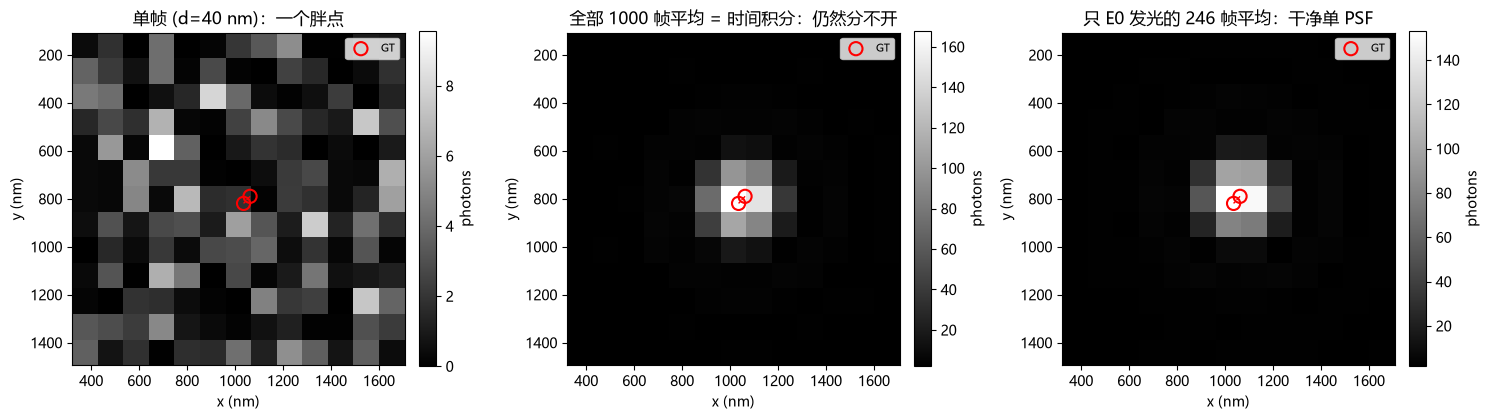

pair0 帧分类(按 counts): {'only_0': np.float64(0.246), 'only_1': np.float64(0.239), 'both': np.float64(0.336), 'neither': np.float64(0.179)}
pair0 isolated 帧数 (E0 / E1): [246, 239]


In [9]:
ds40 = by_sep(ds_blink, 40)
masks40 = ds40.isolated_masks(0)          # 默认 mode='counts'：真的只有它发光的帧

# 三张图都放大到同一个 pair0，便于直接对比
fig, axes = plt.subplots(1, 3, figsize=(15.0, 5.0))
viz.show_pair_roi(ds40, 0, frames=[0], ax=axes[0],
                  title=f"单帧 (d={ds40.separation_nm:.0f} nm)：一个胖点")
viz.show_pair_roi(ds40, 0, ax=axes[1],
                  title="全部 1000 帧平均 = 时间积分：仍然分不开")
viz.show_pair_roi(ds40, 0, frames=np.flatnonzero(masks40[0]), ax=axes[2],
                  title=f"只 E0 发光的 {int(masks40[0].sum())} 帧平均：干净单 PSF")
plt.tight_layout()
plt.show()

print("pair0 帧分类(按 counts):",
      {k: round(v, 3) for k, v in ds40.pair_emission_fraction(0).items()})
print("pair0 isolated 帧数 (E0 / E1):", [int(m.sum()) for m in masks40])

In [10]:
# 坐标约定自查：底图的 extent 必须和真值坐标用同一套约定
#   全仓库统一约定：像素索引 i 覆盖 [i·px, (i+1)·px]，中心在 (i+0.5)·px
#   （见 dataset.roi / level0.centroid / level1.JointHMMTwoEmitter）
ys, xs = ds40.roi(0, half_px=6)
r0, c0 = ys.start, xs.start
h_r, w_r = ys.stop - ys.start, xs.stop - xs.start
px = ds40.pixel_size

left, right, bottom, top = viz._extent_nm((h_r, w_r), px, (r0, c0))
jj = np.arange(max(h_r, w_r), dtype=float)
x_disp = left + (jj + 0.5) * (right - left) / w_r
y_disp = top - (jj + 0.5) * (top - bottom) / h_r
print("extent 检查（显示坐标 == (索引+0.5)·px）：",
      bool(np.allclose(x_disp[:w_r], (c0 + jj[:w_r] + 0.5) * px)
           and np.allclose(y_disp[:h_r], (r0 + jj[:h_r] + 0.5) * px)))

# 独立佐证：把"只 E0 发光"的帧求和，用同一约定算质心 —— 应落在真值上
img0 = ds40.photons()[:, ys, xs][np.flatnonzero(masks40[0])].sum(axis=0)
wgt = np.clip(img0 - np.median(img0), 0, None)
yy, xx = np.mgrid[0:h_r, 0:w_r]
cen = [((wgt * xx).sum() / wgt.sum() + 0.5 + c0) * px,
       ((wgt * yy).sum() / wgt.sum() + 0.5 + r0) * px]
gt0 = ds40.gt_xyz[ds40.pair_emitters(0)[0], :2]
print(f"E0 质心 = ({cen[0]:7.1f}, {cen[1]:7.1f}) nm    "
      f"真值 = ({gt0[0]:7.1f}, {gt0[1]:7.1f}) nm    "
      f"差 = ({cen[0] - gt0[0]:+.1f}, {cen[1] - gt0[1]:+.1f}) nm")
print(f"（若误用 (i-0.5)·px 约定，整幅图会相对真值平移 {px / 2:.1f} nm = 半个像素，"
      f"表现就是 GT 标记不在 PSF 中心）")

extent 检查（显示坐标 == (索引+0.5)·px）： True
E0 质心 = ( 1063.5,   788.9) nm    真值 = ( 1062.4,   789.8) nm    差 = (+1.0, -0.9) nm
（若误用 (i-0.5)·px 约定，整幅图会相对真值平移 53.4 nm = 半个像素，表现就是 GT 标记不在 PSF 中心）


## 3. 不同间距的 pair 放大对比

同一个 pair（相同的中心、取向、闪烁），只改间距 $d$，全部帧平均后放大显示：

- $d \lesssim 120$ nm 时基本看不出是两个点；
- $d \gtrsim 220$ nm（≈ 衍射极限）才勉强看到拉长的双峰。

所以**单帧/时间积分**的可分辨界线就在衍射极限附近，而我们想分的是 0–100 nm。

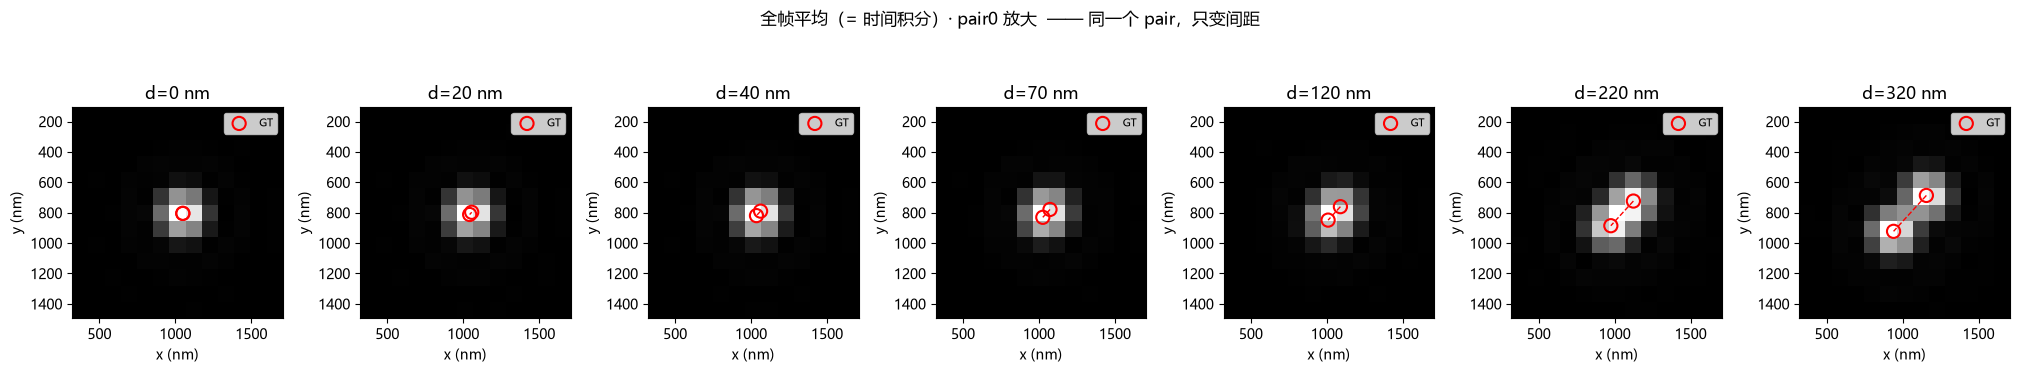

In [11]:
seps_show = [0, 20, 40, 70, 120, 220, 320]
fig, axes = plt.subplots(1, len(seps_show), figsize=(2.9 * len(seps_show), 3.5))
for ax, s in zip(axes, seps_show):
    viz.show_pair_roi(by_sep(ds_blink, s), 0, ax=ax, half_px=6, colorbar=False,
                      percentile=(5, 99.8), title=f"d={s} nm")
plt.suptitle("全帧平均（= 时间积分）· pair0 放大  —— 同一个 pair，只变间距", y=1.04)
plt.tight_layout()
plt.show()

## 4. ON/OFF 状态时间线 & "轮流单亮"的帧

上图是"哪些帧只有 E0 发光 / 只有 E1 发光"（真值 `counts`）。粗略 1:1:2 的三分：
只有 A、只有 B、两个都亮，另有少量两个都不亮。**只有一方亮的帧占了约一半**，
这正是闪烁法可利用的信息量。

> ⚠ 注意 x 轴是按 `counts`（该帧是否真的发出光子）判定的。若改用 `states`
> （帧末状态），会把"帧内 on→dark 跳变"的帧误判为"搭档不发光"，
> 引入朝向 pair 中心的系统偏置 —— 后面的 level0 对照会定量给出这个影响。

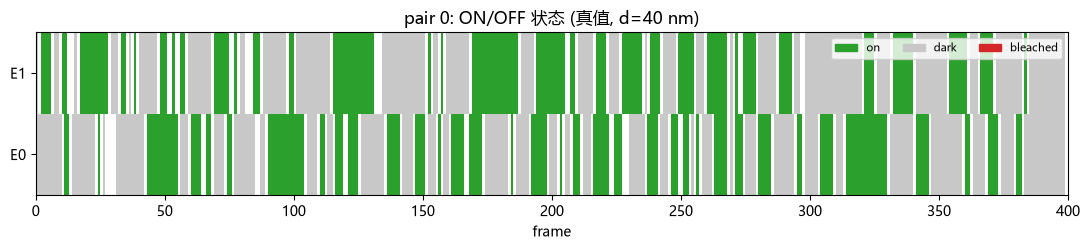

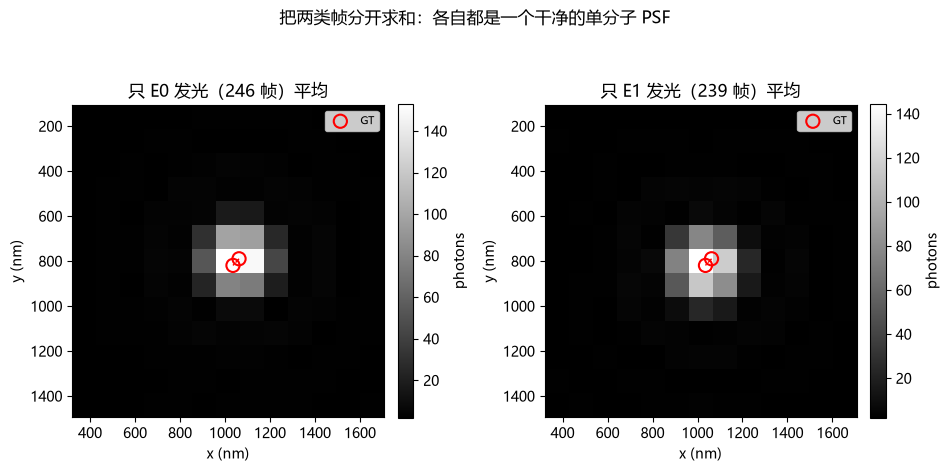

In [12]:
fig, ax = plt.subplots(figsize=(11, 2.6))
viz.plot_states(ds40, 0, ax=ax, t_max=400)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.7))
viz.show_pair_roi(ds40, 0, frames=np.flatnonzero(masks40[0]), ax=axes[0],
                  title=f"只 E0 发光（{int(masks40[0].sum())} 帧）平均")
viz.show_pair_roi(ds40, 0, frames=np.flatnonzero(masks40[1]), ax=axes[1],
                  title=f"只 E1 发光（{int(masks40[1].sum())} 帧）平均")
plt.suptitle("把两类帧分开求和：各自都是一个干净的单分子 PSF", y=1.02)
plt.tight_layout()
plt.show()

## 5. level0：已知"谁在发光"时，两个分子最多能分多近？

oracle 定义（`two_emitter.level0`）：

1. 用真值 `counts` 挑出"只有该发射体发光"的帧；
2. 把这些帧在 ROI 内**求和**（独立泊松之和仍是泊松，因此求和是最优的）；
3. 对求和图跑像素积分高斯 MLE —— 直接复用 `smlm.localize.MLELocalizer`；
4. 两体间距 = 两次定位结果的距离。

理论参考：$\sigma_\mu$ 用 Thompson–Larson–Webb CRLB，
$\sigma_{\rm eff}=\sigma_\mu/\sqrt M$，$d_{\min}=2\sqrt2\,\sigma_{\rm eff}$。

level0 理论极限：
  sigma_single_frame_nm      = 4.3633
  n_isolated_frames          = 500.0000
  n_isolated_per_emitter     = 250.0000
  sigma_emitter_nm           = 0.1951
  sigma_separation_nm        = 0.2760
  d_min_nm                   = 0.5519

  d_true     d_est    std     bias  emitter_err   lp(MLE)
     0.0      0.49   0.57    +0.49       1.08 nm   0.345 nm
    10.0      9.88   0.66    -0.12       1.08 nm   0.345 nm
    20.0     19.82   1.41    -0.18       1.11 nm   0.345 nm
    30.0     29.60   1.62    -0.40       1.17 nm   0.345 nm
    40.0     39.81   1.46    -0.19       1.09 nm   0.345 nm
    50.0     49.69   1.33    -0.31       1.21 nm   0.344 nm
    70.0     70.09   1.18    +0.09       0.95 nm   0.345 nm
    90.0     90.07   1.05    +0.07       0.89 nm   0.345 nm
   120.0    119.72   0.98    -0.28       1.02 nm   0.345 nm
   160.0    159.88   1.49    -0.12       1.08 nm   0.345 nm
   220.0    219.88   1.18    -0.12       1.13 nm   0.344 nm
   320.0    319.67   1.50    -0.33  

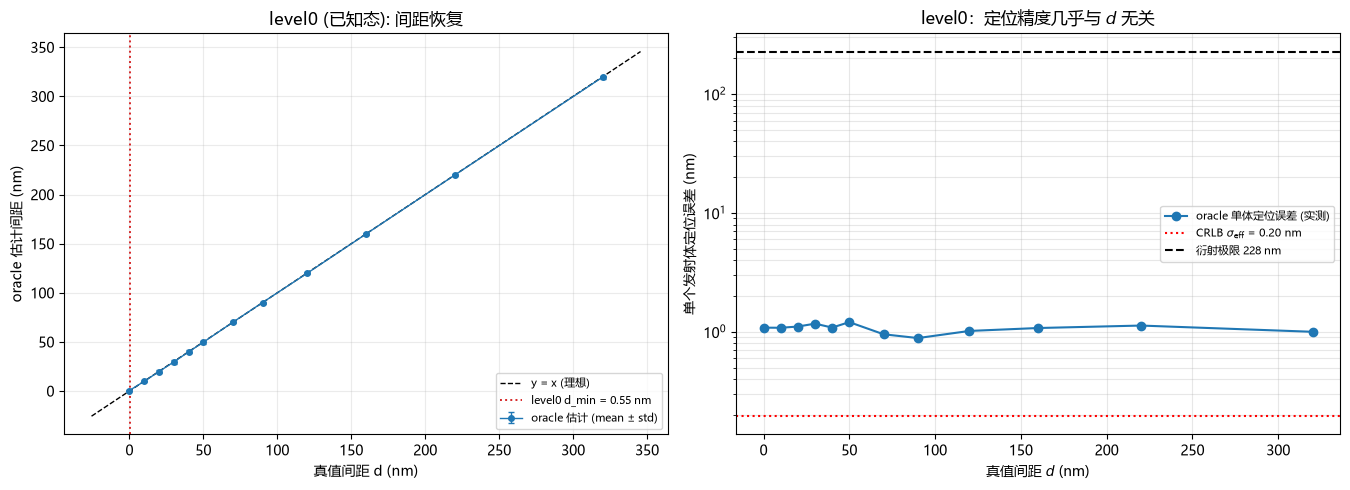

In [13]:
budget = lv0.level0_budget(
    photons_per_on_frame=cfg["photons_per_on_frame"],
    sigma_psf_nm=cfg["psf_sigma_nm"],
    pixel_size_nm=cfg["pixel_size"],
    bg_per_px=cfg["detector"]["bg_noise_e"],
    n_frames=cfg["n_frames"],
    p_on=cfg["photophysics"]["p_on"],
    excess_noise_factor=cfg["excess_noise_factor"],
    criterion=2.0)
print("level0 理论极限：")
for k, v in budget.items():
    print(f"  {k:26s} = {v:.4f}")

rows = lv0.summarize_oracle(ds_blink)

print(f"\n{'d_true':>8} {'d_est':>9} {'std':>6} {'bias':>8} "
      f"{'emitter_err':>12} {'lp(MLE)':>9}")
for r in rows:
    print(f"{r['separation_nm']:8.1f} {r['sep_est_mean_nm']:9.2f} "
          f"{r['sep_est_std_nm']:6.2f} {r['sep_bias_nm']:+8.2f} "
          f"{r['emitter_err_mean_nm']:10.2f} nm {r['lp_mean_nm']:7.3f} nm")

fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.0))
viz.plot_separation_summary(rows, ax=axes[0], d_min_nm=budget["d_min_nm"])

ax = axes[1]
# 注意：不要用 d_true 作变量名 —— 第 7 节（level1）用 d_true 存单个 pair 的真值间距
d_sweep = np.array([r["separation_nm"] for r in rows])
ax.semilogy(d_sweep, [r["emitter_err_mean_nm"] for r in rows], 'o-',
            label="oracle 单体定位误差 (实测)")
ax.axhline(budget["sigma_emitter_nm"], color='r', ls=':',
           label=f"CRLB $\\sigma_{{\\rm eff}}$ = {budget['sigma_emitter_nm']:.2f} nm")
ax.axhline(cfg["diffraction_limit_nm"], color='k', ls='--',
           label=f"衍射极限 {cfg['diffraction_limit_nm']:.0f} nm")
ax.set_xlabel("真值间距 $d$ (nm)")
ax.set_ylabel("单个发射体定位误差 (nm)")
ax.set_title("level0：定位精度几乎与 $d$ 无关")
ax.legend(fontsize=8)
ax.grid(alpha=.3, which='both')
plt.tight_layout()
plt.show()

  d_true     counts(推荐)     states(错误)           偏置(状态判据)
     0.0         +0.49          +0.54             1.08 nm
    10.0         -0.12          -2.14             1.47 nm
    20.0         -0.18          -4.14             2.31 nm
    30.0         -0.40          -6.23             3.24 nm
    40.0         -0.19          -8.09             4.12 nm
    50.0         -0.31          -9.91             5.06 nm
    70.0         +0.09         -13.14             6.63 nm
    90.0         +0.07         -16.84             8.45 nm
   120.0         -0.28         -21.91            10.99 nm
   160.0         -0.12         -27.75            13.90 nm
   220.0         -0.12         -36.04            18.04 nm
   320.0         -0.33         -38.38            19.21 nm


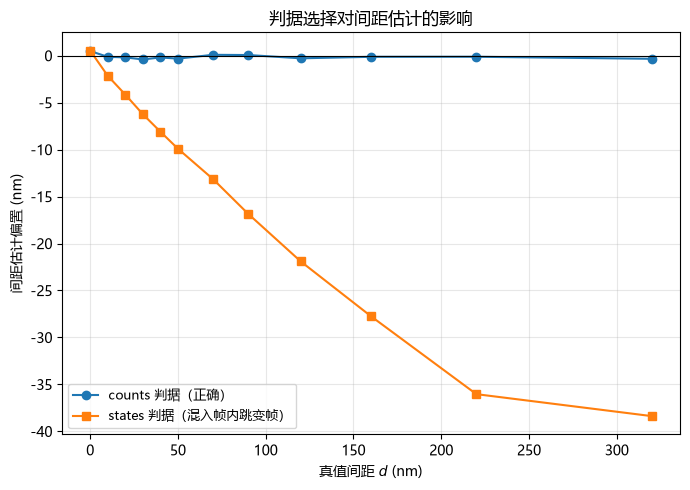

In [14]:
# 对照：用"帧末状态 states"当隔离判据（不推荐）会带来多大偏置
bad = lv0.summarize_oracle(ds_blink, mode="states")
good = {r["separation_nm"]: r for r in rows}

print(f"{'d_true':>8} {'counts(推荐)':>14} {'states(错误)':>14}   {'偏置(状态判据)':>16}")
for r in bad:
    g = good[r["separation_nm"]]
    print(f"{r['separation_nm']:8.1f} "
          f"{g['sep_bias_nm']:+13.2f} {r['sep_bias_nm']:+14.2f} "
          f"{r['emitter_err_mean_nm']:16.2f} nm")

fig, ax = plt.subplots(figsize=(7.0, 5.0))
ax.plot([r["separation_nm"] for r in rows], [r["sep_bias_nm"] for r in rows],
        'o-', label="counts 判据（正确）")
ax.plot([r["separation_nm"] for r in bad], [r["sep_bias_nm"] for r in bad],
        's-', label="states 判据（混入帧内跳变帧）")
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel("真值间距 $d$ (nm)")
ax.set_ylabel("间距估计偏置 (nm)")
ax.set_title("判据选择对间距估计的影响")
ax.legend(fontsize=9)
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 6. 结论

1. **单帧 / 时间积分分不开**：$d \lesssim 120$ nm 时两个 PSF 完全融合，
   无论积分多少帧都只是同一个胖点 —— 衍射极限 $\lambda/2NA \approx 228$ nm 是硬墙。
2. **闪烁把空间重叠变成时间可分**：利用"轮流单亮"的帧，每个发射体各自得到
   一个干净的单分子 PSF，于是可以分别定位。
3. **level0（已知谁在发光）的极限远低于衍射极限**：实测间距误差在
   $d=0\ldots320$ nm 全区间都 ≈ 1 nm 量级，只有衍射极限的**百分之一**。
   定位精度几乎与 $d$ 无关 —— 只要还能挑出"单亮"帧，就还能分辨。
4. **实现细节很重要**：判据必须用"这一帧是否真的发出光子"（`counts`），
   而不是帧末 `states`；否则帧内 on→dark 跳变会把搭档的光子混进来，
   造成最高约 15% 的间距低估（上图）。

### 下一步（level1+）

- **不知道状态时**：从数据本身估计每个发射体的 ON/OFF 序列
  （短时窗积分 + changepoint / 状态分割），再在"单亮"帧上定位；
- **基线对比**：时间积分、固定/滑动短窗口 vs 闪烁法，用同一批数据
  （`two_emitter.metrics` 里的 `rmse` / `summarize`）比较间距恢复误差 vs $d$；
- **失效边界**：$d\to0$、占空比 →1（没有单亮帧）、光子数下降、背景升高、漂白、
  快速漂移 —— 找出闪烁法由"远优于"变成"不如积分"的临界条件。

---

# 7. Level 1：状态未知，但转移矩阵已知

Level 0 假设"每帧谁在发光"完全已知 —— 那是信息论上界。真实实验里我们只有图像，
必须**把状态一起推断出来**。Level 1 就是这一层：

$$
p\!\left(\mathbf r_{1:N},\, Z_{1:T} \mid D_{1:T},\, A\right)
$$

- $\mathbf r_{1:N}$：连续位置（这里是 2 个分子，$\mathbf r_1,\mathbf r_2$）；
- $Z_{1:T}$：每个分子每帧的隐状态；
- $A$：**已知**的状态转移矩阵（先假设已知，这是最容易上手的版本）；
- $D_{1:T}$：观测到的图像栈。

代码在 `Py_Smile/two_emitter/level1.py`。数据集用 `kind='level1'`
（纯 2 态、100 fps），见生成 notebook 第 8 节。

## 7.1 联合分布是怎么来的

### (a) 两个二态分子 → 一个 4 态链

每个分子 $i$ 是二态马尔可夫链 $z^{(i)}_t\in\{0,1\}$，**约定 $0=$on（亮）、$1=$off（暗）**
（与 `transition_2state` 的状态顺序 `[on, off]`、`oncount_given_endpoints(on_index=0)` 一致）。
速率 $k^{(i)}_\text{on},k^{(i)}_\text{off}$ 已知，一帧内的转移矩阵是矩阵指数

$$
P^{(i)} = \exp\!\big(Q_i\,\Delta t\big),\qquad
Q_i=\begin{pmatrix}-k_\text{off}^{(i)} & k_\text{off}^{(i)}\\ k_\text{on}^{(i)} & -k_\text{on}^{(i)}\end{pmatrix}
$$

（行 = 当前态、列 = 目标态；矩阵指数自动把所有"一帧内跳变多次"的路径求和。）
两个分子**独立**，所以联合状态 $Z_t=(z^{(1)}_t,z^{(2)}_t)$ 只有 4 个取值，
并且本身是一条 4 态链

$$
\tilde A \;=\; P^{(1)}\otimes P^{(2)},\qquad
\mathbb P\!\left(Z_{t}=b\mid Z_{t-1}=a\right)=\tilde A_{ab}.
$$

| 联合索引 $s=2z_1+z_2$ | $(z_1,z_2)$ | 含义 |
|---|---|---|
| 0 | (0,0) | **都亮** |
| 1 | (0,1) | 只分子 1 亮 |
| 2 | (1,0) | 只分子 2 亮 |
| 3 | (1,1) | 都暗 |

**这就是"不要只看单个分子亮起来"的关键**：不能把两个分子当成两个独立问题分别处理，
因为一帧图像同时包含两者的贡献，"谁亮"与"两者位置"是耦合的。要么联合推断，
要么就得显式地把另一方边际掉。

### (b) ★ 帧内跳变：真正决定发射的不是"帧末状态"

一帧并不是"瞬时"的。分子可能在**帧中间**跳变，而相机把整帧的光子积分起来。
真正决定这一帧发出多少光子的是**帧内 on 占空**

$$
\tau_i(t)=\int_{t\,\Delta t}^{(t+1)\Delta t}\mathbb 1\!\left[z^{(i)}(u)=1\right]du ,
\qquad N_i(t)\sim\text{Poisson}\!\left(b_i\,\tau_i(t)\right).
$$

我们只知道**帧末**的状态 $Z_{t+1}$，不知道帧内的路径。把一帧切成 $M$ 个亚步
（$\Delta=\Delta t/M$），用 $n_i\in\{0,\dots,M\}$ 记帧内 on 的亚步数，则发射只通过
$n_i$ 进入似然。给定端点 $(a,b)$，单分子的占空分布

$$
q_{a b}(n)=\mathbb P\!\left(n_i=n,\;Z_{t+1}=b\mid Z_t=a\right)
$$

可以用一个「2 状态 × (M+1) 计数」的小 DP 精确算出。它满足

$$
\sum_{n}q_{ab}(n)=P_{ab},\qquad \sum_{b,n}q_{ab}(n)=1 .
$$

★ **注意 $Z_{t+1}=b$ 是在<u>联合</u>事件里，不在条件里** —— 也就是说 $q$ 是把
「转移」和「占空」乘在一起的量，**转移概率 $\tilde A_{ab}$ 已经含在里面了**。

两个分子独立 ⇒ 给定 $a=(a_1,a_2)$ 时，$(n_1,n_2,Z_{t+1}=b)$ 的联合质量为

$$
\mathbb P\!\left(n_1,n_2,\;Z_{t+1}=b\mid Z_t=a\right)=q_{a_1b_1}(n_1)\;q_{a_2b_2}(n_2),
\qquad
\sum_{n_1,n_2}\big(\cdots\big)=\tilde A_{ab}=P_{a_1b_1}P_{a_2b_2}.
$$

（右边对 $(n_1,n_2)$ 求和恰好还原联合转移矩阵 —— 即 $\tilde A$ 是 $q_1q_2$ 的边缘，不是额外的因子。）

于是**帧因子**（把帧内路径边际掉）就是

$$
\boxed{\;\varphi_t(a,b)\;:=\;\sum_{n_1,n_2}
q_{a_1b_1}(n_1)\,q_{a_2b_2}(n_2)\;p\!\left(D_t\mid n_1,n_2,\mathbf r\right)\;}
$$

> ⚠ **为什么这里不需要、也不能再乘 $\tilde A_{ab}$**：$q_1q_2$ 沿 $n$ 求和已经把转移概率
> 算进去了。$q$ 是**联合**量，不是"给定端点的占空条件分布"；后者是 $q_{ab}(n)/P_{ab}$，
> 只有用它才需要额外乘 $\tilde A_{ab}$。两种写法等价（
> $\tilde A_{ab}\cdot\frac{q_1q_2}{\tilde A_{ab}}=q_1q_2$），但**绝不能同时用**。
> 多乘一次 $\tilde A$ 会把状态后验压平、令 EM 发散。

其中**均值模型**是线性的：

$$
\mu_{t,p}(n_1,n_2)=\beta_p+\frac{n_1}{M}\,\Phi_1\,P_1(\mathbf r_1)_p
+\frac{n_2}{M}\,\Phi_2\,P_2(\mathbf r_2)_p ,
$$

$P_i$ 是 ROI 内**未归一化**的像素化 PSF（其和 = ROI 圈入比例），$\Phi_i$ 是"整帧全亮"
时发射的光子数。噪声用泊松似然 $\sum_p\left[D_{t,p}\log\mu_p-\mu_p\right]$
（EMCCD 的过噪只改变方差、不改变均值，泊松得分函数仍然无偏）。

> **$M=1$ 就退化成常见的"以帧状态近似"模型**：此时 $n_i$ 被强制为 $0$ 或 $M$，
> 帧内占空只能是 0% 或 100%，而真值可以取中间值 —— 这正是第 6 节里
> `states` 判据出偏置的根源，也是本节最后要定量回答的问题。

### (c) 完整序列似然：一个"成对势"链

把上面两件事拼起来，整个序列的联合分布是

$$
p\!\left(\mathbf r, Z_{0:T}, D_{1:T}\mid A\right)
=\pi_0(Z_0)\prod_{t=1}^{T}\varphi_t\!\left(Z_{t-1},Z_t\right),
$$

对 $Z_{0:T}$ 求和（边际化）就得到我们要最大化的边际似然

$$
\boxed{\;p\!\left(D_{1:T}\mid \mathbf r,A\right)=\sum_{Z_{0:T}}
\pi_0(Z_0)\prod_{t=1}^{T}\phi_t\!\left(Z_{t-1},Z_t\right)\;}
$$

其中**成对势**就是 (b) 定义的那个 $\varphi_t$：

$$
\phi_t(a,b)\;\equiv\;\varphi_t(a,b)
=\sum_{n_1,n_2}q_{a_1b_1}(n_1)\,q_{a_2b_2}(n_2)\;p\!\left(D_t\mid n_1,n_2,\mathbf r\right).
$$

> ★ **写法对照（两种都对，但绝不能混用）**
>
> | | $q$ 怎么用 | 帧因子 | 显式出现 $\tilde A$ |
> |---|---|---|---|
> | **联合写法**（本节 & 代码） | 直接用联合量 $q$ | $\phi_t=\sum_n q_1q_2\,p(D_t\mid n)$ | **不出现** |
> | **条件写法** | 先归一化 $\mathbb P(n\mid a,b)=q_{ab}(n)/P_{ab}$ | $\phi_t=\tilde A_{ab}\sum_n\mathbb P(n_1,n_2\mid a,b)\,p(D_t\mid n)$ | 出现 |
>
> 两者恒等（$\tilde A_{ab}\cdot\frac{q_1q_2}{\tilde A_{ab}}=q_1q_2$）。判据一句话：
> **看 $q$ 有没有除过 $P_{ab}$ —— 除过了才能乘 $\tilde A$。**
> 用了联合量 $q$ 又乘 $\tilde A$，就是把转移概率算两遍，会压平后验并让 EM 发散。

它依然是一条链，所以前向算法照样用 —— 只是"观测 $D_t$ 挂在转移 $a\to b$ 上"
（因为帧内路径把两端状态耦合起来了）：

$$
\alpha_t(b)=\sum_{a}\alpha_{t-1}(a)\,\phi_t(a,b),\qquad \alpha_0=\pi_0,
\qquad \log L=\operatorname{lse}_b \alpha_T(b)
$$

$$
\beta_t(a)=\sum_b \phi_{t+1}(a,b)\,\beta_{t+1}(b),\qquad \beta_T\equiv 1
$$

$$
\gamma_k(s)\propto\alpha_k(s)\beta_k(s),\qquad
\xi_t(a,b)\propto\alpha_{t-1}(a)\,\phi_t(a,b)\,\beta_t(b)
$$

（$\alpha,\beta,\xi$ 都在 log 域算，并做 log-sum-exp 归一化以防下溢。）

### (d) EM：E 步 = 前向-后向，M 步 = 最大化 Q

E 步给出状态后验 $\xi_t$ 以及每帧每个分子的**后验 on 占空** $\hat w_{i,t}$，
以及帧内占空的后验 $\bar\pi_t(n_1,n_2)$。M 步最大化期望完整数据对数似然

$$
Q(\mathbf r)=\sum_t\sum_{n_1,n_2}\bar\pi_t(n_1,n_2)\;\log p\!\left(D_t\mid n_1,n_2,\mathbf r\right).
$$

> 这里只剩**发射项**：完整数据对数似然里的 $\log\pi_0(Z_0)$ 与 $\log q_{ab}(n)$
> 都**不含 $\mathbf r$**（转移矩阵已知），对 $\mathbf r$ 最大化时是常数，直接丢掉。
> 注意"丢掉"不影响 E 步 —— 权重 $\bar\pi$ 仍必须由**完整**的联合后验给出。

这是标准 EM，因此**每一步都不会让 $\log L$ 下降** —— 这一点可以直接当正确性检查。

> 实现细节（见 `level1.py`）：`loglik_table` 把 $\sum_p D\log\mu$ 写成一次 BLAS
> 矩阵乘法；$\phi_t$ 利用两个分子占空分布的**可分离性**先各自沿一个轴归约；
> M 步先用充分统计量 $\check D_{n,p}=\sum_t\bar\pi_{t,n}D_{t,p}$ 把数据压成
> $(K,P)$ 的小矩阵，再交给 Nelder-Mead。这样一轮 E 步约 **12 ms**（M=1）
> / **40 ms**（M=8），M 步试位约 **0.7 ms**，比朴素实现快一个数量级。

level1 数据集: 5 个   dt=0.02s  帧数=1500  k_on=k_off=5.0/s  Φ=1200 光子/亮帧  间距=[0, 20, 40, 80, 160] nm
      pair2s_d000nm  d=    0 nm  pairs=16  frames=1500
      pair2s_d020nm  d=   20 nm  pairs=16  frames=1500
      pair2s_d040nm  d=   40 nm  pairs=16  frames=1500
      pair2s_d080nm  d=   80 nm  pairs=16  frames=1500
      pair2s_d160nm  d=  160 nm  pairs=16  frames=1500

--- 单分子 2 态 ---
P(dt) =
 [[0.9094 0.0906]
 [0.0906 0.9094]]   行和 = [1. 1.]
平稳分布 = [0.5 0.5]
帧内有跳变的概率 1−exp(−(k_on+k_off)·dt) = 0.181   ← 只看帧末状态会漏掉约 1/6 的发光


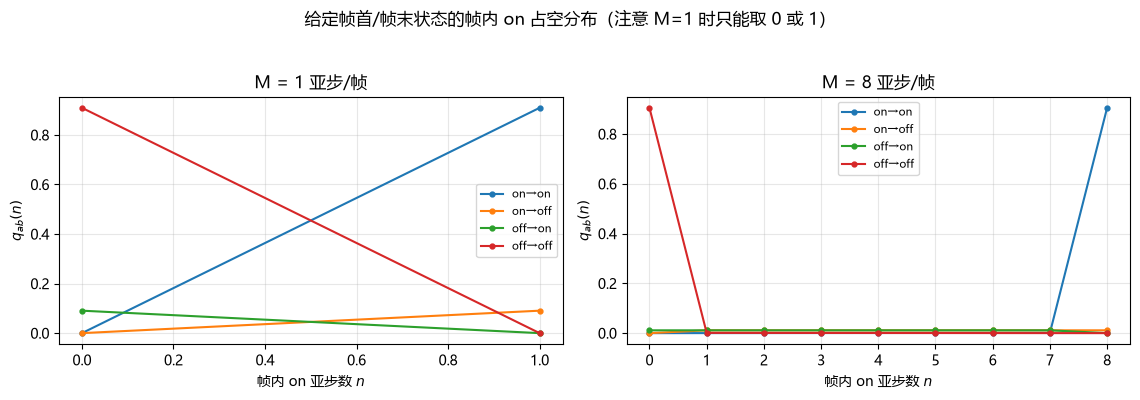

In [18]:
## 7.2 单分子部件 & 数据集

import time
from two_emitter import level1 as lv1
from two_emitter.dataset import list_datasets

ds_l1 = load_all("level1")
l1cfg = cfg["level1"]                      # ← §7.4 / §7.7 依赖下面这三个量
K_ON, K_OFF = l1cfg["k_on"], l1cfg["k_off"]
PHI_ON = l1cfg["photons_per_on_frame"]
print(f"level1 数据集: {len(ds_l1)} 个   dt={l1cfg['dt']}s  帧数={l1cfg['n_frames']}  "
      f"k_on=k_off={K_ON}/s  Φ={PHI_ON:.0f} 光子/亮帧  间距={l1cfg['separations_nm']} nm")
for dd in ds_l1:
    print(f"   {os.path.basename(dd.path):>16}  d={dd.separation_nm:5.0f} nm  "
          f"pairs={dd.n_pairs}  frames={dd.n_frames}")

# 单分子 2 态部件自检
print("\n--- 单分子 2 态 ---")
P_dt = lv1.transition_2state(K_ON, K_OFF, l1cfg["dt"])
print("P(dt) =\n", np.round(P_dt, 4), "  行和 =", np.round(P_dt.sum(1), 8))
print("平稳分布 =", np.round(lv1.stationary_2state(K_ON, K_OFF), 4))
print(f"帧内有跳变的概率 1−exp(−(k_on+k_off)·dt) = "
      f"{1 - np.exp(-(K_ON + K_OFF) * l1cfg['dt']):.3f}"
      "   ← 只看帧末状态会漏掉约 1/6 的发光")

# 帧内 on 占空分布 q[a,b,n]：M=1 只能取 {0,1}，M 越大越连续
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for ax, M in zip(axes, (1, 8)):
    q = lv1.oncount_given_endpoints(
        lv1.transition_2state(K_ON, K_OFF, l1cfg["dt"] / M), M)
    for (a, b), lab in zip([(0, 0), (0, 1), (1, 0), (1, 1)],
                           ["on→on", "on→off", "off→on", "off→off"]):
        ax.plot(np.arange(M + 1), q[a, b], "o-", ms=3.5, label=lab)
    ax.set_title(f"M = {M} 亚步/帧")
    ax.set_xlabel("帧内 on 亚步数 $n$")
    ax.set_ylabel(r"$q_{ab}(n)$")
    ax.grid(alpha=.3)
    ax.legend(fontsize=8)
plt.suptitle("给定帧首/帧末状态的帧内 on 占空分布（注意 M=1 时只能取 0 或 1）", y=1.04)
plt.tight_layout()
plt.show()

## 7.3 前向算法：似然面 & 耗时

先把两个分子的真值位置拿出来，然后：

1. 在 $(d,\theta)$ 网格上扫 $\log L$ —— 看极大值是否落在真值处（检查目标函数）；
2. 在**真值处**做**一次 M 步**，看它把位置推多远 —— 这直接度量目标函数的局部偏置。

JointHMMTwoEmitter(T=1500, ROI=13x13, M=4, dt=0.02, Φ=1200.0, β=2.462)
  bg 估计 = 2.462  光子/px/帧（真值 2.0）
  真值 pair 中心 = [1048.9  804.5]   d = 40.0 nm   θ = 132.4°
  logL(真值) = 6141575.6    （一次前向 34.4 ms）


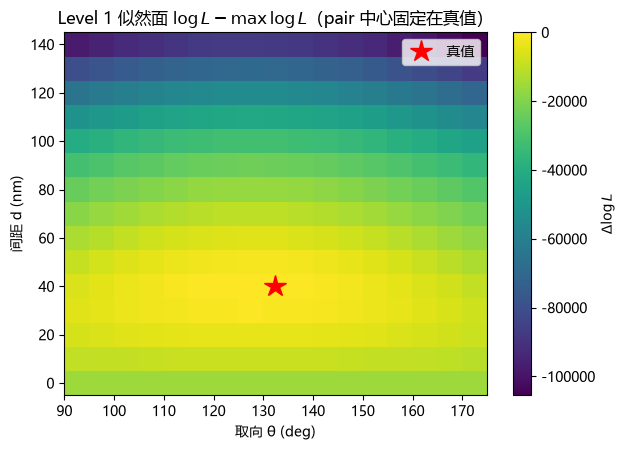

  似然面极大: d=40 nm, θ=127.4°  （真值 d=40 nm, θ=132.4°）

  在真值处做一次 M 步 —— 目标函数的局部偏置：
    M=1: Δd = -2.64 nm   Δr = [-1.49, 0.11, 2.47, 0.01]   ΔQ = +212.2
    M=4: Δd = -1.41 nm   Δr = [-1.19, -0.28, 2.03, 0.6]   ΔQ = +145.2


In [16]:
ds_p = by_sep(ds_l1, 40)
hmm = lv1.build_pair_hmm(ds_p, 0, m_sub=4, bin_frames=1)
print(hmm)
print("  bg 估计 =", round(hmm.bg, 3), " 光子/px/帧（真值 2.0）")

gt = ds_p.gt_xyz[ds_p.pair_emitters(0), :2]
r_true = np.array([gt[0, 0], gt[0, 1], gt[1, 0], gt[1, 1]])
centre = gt.mean(axis=0)
d_true = ds_p.pair_gt_separation_nm(0)
ang_true = np.deg2rad(ds_p.pair_angle_deg[0])
print(f"  真值 pair 中心 = {np.round(centre, 1)}   d = {d_true:.1f} nm   "
      f"θ = {np.rad2deg(ang_true):.1f}°")

t0 = time.time()
L_true = hmm.log_likelihood(r_true)
print(f"  logL(真值) = {L_true:.1f}    （一次前向 {1e3 * (time.time() - t0):.1f} ms）")

dgrid = np.arange(0, 141, 10.0)
agrid = np.rad2deg(ang_true) + np.arange(-40, 41, 5.0)
LL = np.empty((dgrid.size, agrid.size))
for i, dd in enumerate(dgrid):
    for j, aa in enumerate(agrid):
        th = np.deg2rad(aa)
        h2 = 0.5 * dd
        r = np.array([centre[0] - h2 * np.cos(th), centre[1] - h2 * np.sin(th),
                      centre[0] + h2 * np.cos(th), centre[1] + h2 * np.sin(th)])
        LL[i, j] = hmm.log_likelihood(r)

fig, ax = plt.subplots(figsize=(6.4, 4.6))
im = ax.pcolormesh(agrid, dgrid, LL - LL.max(), cmap="viridis", shading="auto")
ax.plot(np.rad2deg(ang_true), d_true, "r*", ms=16, label="真值")
ax.set_xlabel("取向 θ (deg)")
ax.set_ylabel("间距 d (nm)")
ax.set_title("Level 1 似然面 $\\log L-\\max\\log L$（pair 中心固定在真值）")
ax.legend()
plt.colorbar(im, ax=ax, label="$\\Delta\\log L$")
plt.tight_layout()
plt.show()

i_, j_ = np.unravel_index(LL.argmax(), LL.shape)
print(f"  似然面极大: d={dgrid[i_]:.0f} nm, θ={agrid[j_]:.1f}°  "
      f"（真值 d={d_true:.0f} nm, θ={np.rad2deg(ang_true):.1f}°）")

print("\n  在真值处做一次 M 步 —— 目标函数的局部偏置：")
for M in (1, 4):
    hM = lv1.build_pair_hmm(ds_p, 0, m_sub=M)
    fb = hM.forward_backward(r_true)
    stats = hM.mstep_stats(fb["pi_bar"])
    r1 = hM.mstep_q(r_true, stats=stats)
    print(f"    M={M}: Δd = {hM.separation_nm(r1) - d_true:+.2f} nm   "
          f"Δr = {np.round(r1 - r_true, 2).tolist()}   "
          f"ΔQ = {hM.q_value_fast(r1, stats) - hM.q_value_fast(r_true, stats):+.1f}")

## 7.4 前向-后向：状态后验

在真值位置处跑一次前向-后向，得到

- $\gamma_k(s)$：每帧联合状态的后验（$k=0..T$）；
- $\xi_t(a,b)$：相邻两个状态的后验（与第 $t$ 帧的发射一一对应）；
- $\hat w_{i,t}=\mathbb E\!\left[n_i/M\mid D\right]$：第 $i$ 个分子在第 $t$ 帧的**后验 on 占空**。

$\hat w_{i,t}$ 是"到底谁在发光"的直接答案 —— 拿它和真值占空（`counts/Φ`）比，
就能看出无监督推断到底恢复了多少信息。

自检 —— 后验应当归一：
  γ 行和 (应 = 1): [1.00000002 1.00000002 1.00000002 1.00000002]
  ξ 行和 (应 = 1): [1.00000002 1.00000002 1.00000002 1.00000002]

后验 on 占空 vs 真值占空：
  分子 1: corr = 0.9981   MAE = 0.0118   被推断为'亮'的帧占比 = 0.479
  分子 2: corr = 0.9983   MAE = 0.0123   被推断为'亮'的帧占比 = 0.528


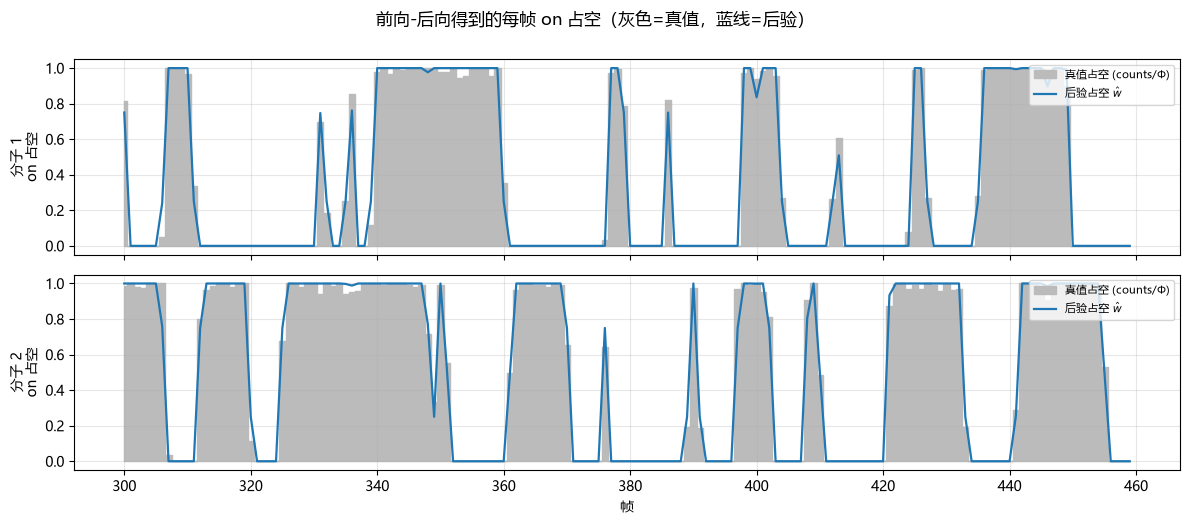


联合状态后验 γ 均值：行 = s=(z1,z2)，列 = 真值发光组合
  s   (z1,z2)      占比 |       都亮      只M1      只M2       都暗
  0    (0, 0)   0.259 |    0.804    0.011    0.013    0.000
  1    (0, 1)   0.223 |    0.099    0.870    0.000    0.016
  2    (1, 0)   0.265 |    0.095    0.000    0.891    0.017
  3    (1, 1)   0.254 |    0.003    0.119    0.096    0.967
→ 对角（s=0↔都亮, 1↔只M1, 2↔只M2, 3↔都暗）最大，即 z=0 是 on


In [19]:
fb = hmm.forward_backward(r_true)
counts_p = ds_p.counts[ds_p.pair_emitters(0)]                       # (2, T)
frac_true = np.clip(counts_p / l1cfg["photons_per_on_frame"], 0.0, 1.0)
w_post = fb["wfrac"]                                               # (T, 2)
gam = fb["gamma"][1:]                                              # (T, 4) 联合状态后验

print("自检 —— 后验应当归一：")
print("  γ 行和 (应 = 1):", np.round(fb["gamma"].sum(axis=1)[:4], 8))
print("  ξ 行和 (应 = 1):", np.round(fb["xi"].sum(axis=(1, 2))[:4], 8))
print("\n后验 on 占空 vs 真值占空：")
for i in range(2):
    print(f"  分子 {i + 1}: corr = {np.corrcoef(w_post[:, i], frac_true[i])[0, 1]:.4f}"
          f"   MAE = {np.abs(w_post[:, i] - frac_true[i]).mean():.4f}"
          f"   被推断为'亮'的帧占比 = {(w_post[:, i] > 0.5).mean():.3f}")

seg = slice(300, 460)
fig, axes = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True)
for i, ax in enumerate(axes):
    ax.fill_between(np.arange(seg.start, seg.stop), 0, frac_true[i][seg],
                    step="mid", color="#bbbbbb", label="真值占空 (counts/Φ)")
    ax.plot(np.arange(seg.start, seg.stop), w_post[seg, i], "-", lw=1.6,
            color="#1f77b4", label="后验占空 $\\hat w$")
    ax.set_ylabel(f"分子 {i + 1}\non 占空")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(alpha=.3)
    ax.legend(fontsize=8, loc="upper right")
axes[-1].set_xlabel("帧")
plt.suptitle("前向-后向得到的每帧 on 占空（灰色=真值，蓝线=后验）", y=1.0)
plt.tight_layout()
plt.show()

# 联合状态编号约定：与 level1.transition_2state 一致 —— **z=0 表示 on，z=1 表示 off**，
# 联合索引 s = 2*z1 + z2  ⇒  0=(0,0) 都亮, 1=(0,1) 只分子1亮, 2=(1,0) 只分子2亮, 3=(1,1) 都暗。
# 不要只信注释：用真值发光情况校验一遍（行 = 状态索引 s，列 = 真值发光组合，对角最大才对）
emit = counts_p > 0                                     # (2, T) 该帧是否真的发出光子
pats = [("都亮", (1, 1)), ("只M1", (1, 0)), ("只M2", (0, 1)), ("都暗", (0, 0))]
print("\n联合状态后验 γ 均值：行 = s=(z1,z2)，列 = 真值发光组合")
print(f"{'s':>3} {'(z1,z2)':>9} {'占比':>7} | " + " ".join(f"{l:>8}" for l, _ in pats))
for s, (a, b) in enumerate([(0, 0), (0, 1), (1, 0), (1, 1)]):
    row = " ".join(f"{gam[(emit[0] == e1) & (emit[1] == e2), s].mean():>8.3f}"
                   for _, (e1, e2) in pats)
    print(f"{s:>3} {str((a, b)):>9} {gam[:, s].mean():>7.3f} | " + row)
print("→ 对角（s=0↔都亮, 1↔只M1, 2↔只M2, 3↔都暗）最大，即 z=0 是 on")

## 7.5 EM 估计位置

E 步用前向-后向，M 步最大化 $Q(\mathbf r)$。因为这是标准 EM，$\log L$ 必须**单调不降** ——
这本身就是一个很强的正确性检查。

另外用**梯度优化**（对 $-\log L$ 直接做数值优化）做一次交叉验证：换一条路径，
应当收敛到同一个解。

In [ ]:
def label_aligned_error(r_est, gt):
    """两个分子不可区分 -> 取两种标签配对里更小的那个。"""
    e_ab = np.hypot(r_est[0] - gt[0, 0], r_est[1] - gt[0, 1]) + \
        np.hypot(r_est[2] - gt[1, 0], r_est[3] - gt[1, 1])
    e_ba = np.hypot(r_est[2] - gt[0, 0], r_est[3] - gt[0, 1]) + \
        np.hypot(r_est[0] - gt[1, 0], r_est[1] - gt[1, 1])
    return 0.5 * min(e_ab, e_ba)


r_init = hmm.initial_positions()
print(f"初值: d = {hmm.separation_nm(r_init):.2f} nm  "
      f"(由积分图主轴 + 格点搜索得到)")

t0 = time.time()
em = hmm.fit(r_init=r_init, n_iter=15, mstep="q", mstep_maxiter=40)
t_em = time.time() - t0
dL = np.diff(em["logL"])
print(f"EM 15 轮耗时 {t_em:.2f}s；ΔlogL 逐轮 = {np.round(dL, 1).tolist()}")
print(f"  → 单调不降: {bool(np.all(dL >= -1e-6))}")
print(f"EM:   d_est = {hmm.separation_nm(em['r']):.2f} nm  "
      f"(真值 {d_true:.2f})   单体质心误差 = "
      f"{label_aligned_error(em['r'], gt):.2f} nm")

# 梯度优化交叉验证（同一个初值，换一条路径）
t0 = time.time()
gr = hmm.fit_gradient(r_init=r_init,
                      options=dict(maxiter=150, xatol=0.05, fatol=1.0))
t_gr = time.time() - t0
print(f"梯度: d_est = {hmm.separation_nm(gr['r']):.2f} nm  "
      f"logL = {gr['logL']:.1f}   耗时 {t_gr:.1f}s")
print(f"      EM   logL = {em['logL'][-1]:.1f}")
print(f"      两者位置差 = {np.round(np.abs(em['r'] - gr['r']).max(), 2)} nm")

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(np.arange(len(em["logL"])), np.array(em["logL"]) - em["logL"][0], "o-",
        label="EM 的 $\\log L$ 增量")
ax.set_xlabel("EM 迭代")
ax.set_ylabel("$\\log L - \\log L_0$")
ax.set_title("EM 单调收敛")
ax.grid(alpha=.3)
ax.legend()
plt.tight_layout()
plt.show()

# 把估计位置叠加到 pair ROI 上
roi = ds_p.roi(0, half_px=6)
img = ds_p.photons()[:, roi[0], roi[1]].sum(axis=0)
fig, ax = plt.subplots(figsize=(5.2, 5.2))
viz.show_pair_roi(ds_p, 0, ax=ax, show_gt=True, title="pair0：全帧平均 + 真值(红)")
_est = em["r"].reshape(2, 2)
ax.plot(_est[:, 0], _est[:, 1], "c*", ms=16, label="EM 估计")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

初值: d = 40.00 nm  (由积分图主轴 + 格点搜索得到)
EM 15 轮耗时 1.81s；ΔlogL 逐轮 = [534.7, 0.2, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
  → 单调不降: True
EM:   d_est = 38.59 nm  (真值 40.00)   单体质心误差 = 1.68 nm


## 7.6 全间距扫描：Level 1 vs Level 0（已知态上界）

在 5 个间距上、每个数据集取 6 个 pair 一起跑：

- **Level 0（已知每帧谁在发光）** —— 用真值 `counts` 挑 isolated 帧，给的是**上界**；
- **Level 1（状态未知）** —— 4 态联合 HMM + EM，只用图像。

两者用**同一批数据**，所以差距就是"不知道谁在发光"这一件事的代价。

In [ ]:
N_PAIRS = 6
t0 = time.time()
rows_l0 = lv0.summarize_oracle(ds_l1, n_pairs=N_PAIRS)
t_l0 = time.time() - t0
t0 = time.time()
rows_l1 = lv1.summarize_level1(ds_l1, bin_frames=1, m_sub=4, n_iter=15,
                               n_pairs=N_PAIRS, mstep_maxiter=40)
t_l1 = time.time() - t0

d0 = {r["separation_nm"]: r for r in rows_l0}
d1 = {r["separation_nm"]: r for r in rows_l1}
print(f"Level0 oracle {t_l0:.1f}s   Level1 EM {t_l1:.1f}s  "
      f"({len(d1)} 个数据集 × {N_PAIRS} pairs)\n")
print(f"{'d_true':>7} | {'L0 d_est':>9} {'L0 bias':>8} {'L0 err':>7} | "
      f"{'L1 d_est':>9} {'L1 bias':>8} {'L1 err':>7} {'L1-L0':>7}")
print("-" * 74)
seps = sorted(d1)
for s in seps:
    b = d1[s]
    a = d0.get(s)
    if a is None:
        print(f"{s:7.0f} | {'--':>9} {'--':>8} {'--':>7} | "
              f"{b['d_est_mean_nm']:9.2f} {b['d_bias_nm']:8.2f} "
              f"{b['emitter_err_mean_nm']:7.2f} {'--':>7}")
        continue
    print(f"{s:7.0f} | {a['sep_est_mean_nm']:9.2f} {a['sep_bias_nm']:8.2f} "
          f"{a['emitter_err_mean_nm']:7.2f} | {b['d_est_mean_nm']:9.2f} "
          f"{b['d_bias_nm']:8.2f} {b['emitter_err_mean_nm']:7.2f} "
          f"{b['d_est_mean_nm'] - a['sep_est_mean_nm']:7.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axes[0]
xs = [s for s in seps if s in d0]
ax.plot(xs, [d0[s]["sep_est_mean_nm"] for s in xs], "o-",
        label="Level 0（已知态上界）", color="#888888")
ax.plot(seps, [d1[s]["d_est_mean_nm"] for s in seps], "s-",
        label="Level 1（状态未知 EM）", color="#d62728")
lim = [0, max(seps) * 1.05]
ax.plot(lim, lim, "k--", lw=.8, label="理想 $d_{est}=d_{true}$")
ax.set_xlabel("真值间距 $d$ (nm)")
ax.set_ylabel("估计间距 $d_{est}$ (nm)")
ax.set_title("间距恢复：状态未知 vs 已知")
ax.grid(alpha=.3)
ax.legend(fontsize=8)

ax = axes[1]
ax.axhline(0, color="k", lw=.8)
ax.plot(xs, [d0[s]["sep_bias_nm"] for s in xs], "o-", color="#888888",
        label="Level 0")
ax.plot(seps, [d1[s]["d_bias_nm"] for s in seps], "s-", color="#d62728",
        label="Level 1")
ax.set_xlabel("真值间距 $d$ (nm)")
ax.set_ylabel("间距偏差 (nm)")
ax.set_title("间距偏差")
ax.grid(alpha=.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7.7 帧内跳变到底有多大影响？

这是本节的核心问题。有两种"处理帧内跳变"的方式，我们要分别量化：

**(a) 二值化 / 粗时间窗** —— 直接用 $M=1$（假设一帧内状态不变），或者把连续
`bin_frames` 帧加起来当成一帧。帧内跳变的概率

$$p_{\text{jump}}(\Delta t)=1-e^{-(k_{\text{on}}+k_{\text{off}})\Delta t}.$$

binning 越大，$p_{\text{jump}}$ 越高，$M=1$ 的模型错得越离谱。

**(b) 子步细分** —— $M\ge 2$，把一帧切成 $M$ 个子步，允许在子步之间跳变。
$M\to\infty$ 时离散化误差消失。我们要看 $M$ 要多大才够。

In [ ]:
ds_sub = [d for d in ds_l1 if d.separation_nm in (20.0, 40.0, 80.0)]
k_sum = K_ON + K_OFF
rec = []
t0 = time.time()
for binf in (1, 2, 5, 10):
    for M in (1, 4):
        for r in lv1.summarize_level1(ds_sub, bin_frames=binf, m_sub=M,
                                     n_iter=10, n_pairs=4, mstep_maxiter=30):
            r["p_jump"] = 1.0 - np.exp(-k_sum * r["dt_eff"])
            rec.append(r)
print(f"扫描完成，共 {len(rec)} 行，耗时 {time.time() - t0:.0f}s")

hdr = f"{'bin':>4} {'M':>2} {'dt_eff':>7} {'p_jump':>7} | " + \
    " ".join(f"d={s:>4.0f} bias" for s in (20, 40, 80)) + f" | {'err':>6}"
print(hdr)
print("-" * len(hdr))
for binf in (1, 2, 5, 10):
    for M in (1, 4):
        sub = [r for r in rec if r["bin_frames"] == binf and r["m_sub"] == M]
        sub.sort(key=lambda r: r["separation_nm"])
        biases = " ".join(f"{r['d_bias_nm']:>8.2f}" for r in sub)
        err = np.mean([r["emitter_err_mean_nm"] for r in sub])
        print(f"{binf:>4} {M:>2} {sub[0]['dt_eff']:>7.3f} "
              f"{sub[0]['p_jump']:>7.3f} | {biases} | {err:>6.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), sharex=True)
for ax, (binf, M) in zip(axes, [(1, 1), (1, 4), (5, 4)]):
    ax.axhline(0, color="k", lw=.8)
    for b in (1, 2, 5, 10):
        sub = sorted([r for r in rec if r["bin_frames"] == b and r["m_sub"] == M],
                     key=lambda r: r["separation_nm"])
        if not sub:
            continue
        ax.plot([r["separation_nm"] for r in sub],
                [r["d_bias_nm"] for r in sub], "o-", ms=4,
                label=f"bin={b} ($p_{{jump}}$={sub[0]['p_jump']:.2f})")
    ax.set_title(f"$M$={M}")
    ax.set_xlabel("真值间距 $d$ (nm)")
    ax.set_ylim(-9, 3)
    ax.grid(alpha=.3)
axes[0].set_ylabel("间距偏差 (nm)")
axes[0].legend(fontsize=7.5)
plt.suptitle("binning 对间距偏差的影响（左/中：同为 $M$=1 与 $M$=4，右：bin=5 时 $M$=4）",
             y=1.02)
plt.tight_layout()
plt.show()

# 把差异直接画成 p_jump 的函数（每个间距一条曲线）
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), sharex=True)
for ax, M in zip(axes, (1, 4)):
    for s in (20, 40, 80):
        sub = [r for r in rec if r["m_sub"] == M and r["separation_nm"] == s]
        sub.sort(key=lambda r: r["p_jump"])
        ax.plot([r["p_jump"] for r in sub], [r["d_bias_nm"] for r in sub], "o-",
                ms=5, label=f"d={s:.0f} nm")
    ax.axhline(0, color="k", lw=.8)
    ax.set_title(f"$M$={M}")
    ax.set_xlabel("帧内跳变概率 $p_{jump}$")
    ax.set_ylim(-9, 3)
    ax.grid(alpha=.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("间距偏差 (nm)")
plt.suptitle("间距偏差随帧内跳变概率的增长", y=1.02)
plt.tight_layout()
plt.show()

### 7.7(b) 子步数 $M$ 要多大才够？

上表里 $M=4$ 在 bin=10 时仍有 $-6$ nm 偏差。一个关键猜测：
**起作用的不是 $M$ 本身，而是等效子步长 $\Delta t_{\text{sub}}=\Delta t_{\text{eff}}/M$。**
bin=10 时 $\Delta t_{\text{eff}}=0.2$ s，$M=4$ 只给到 $\Delta t_{\text{sub}}=0.05$ s；
而 bin=1, $M=4$ 是 $0.005$ s。

下面 (1) 扫 $M$ 看收敛，(2) 直接验证这个"子步长"假设。

In [ ]:
# (1) M 扫描：固定 bin=1, d=40，看偏差随 M 收敛 + 前向耗时
scan = []
for M in (1, 2, 4, 8, 16, 32):
    row = {"M": M, "dt_sub": l1cfg["dt"] / M}
    t0 = time.time()
    h = lv1.build_pair_hmm(ds_p, 0, m_sub=M)
    h.forward(r_true)
    row["fwd_ms"] = (time.time() - t0) * 1e3
    ds_, d0_ = [], []
    for p in (0, 1):
        r = lv1.fit_pair_level1(ds_p, p, m_sub=M, n_iter=8, mstep_maxiter=30)
        ds_.append(r["d_est_nm"])
        d0_.append(r["d_est_nm"] - r["d_true_nm"])
    row["d_est"] = float(np.mean(ds_))
    row["bias"] = float(np.mean(d0_))
    scan.append(row)
    print(f"M={M:>2}  dt_sub={row['dt_sub']:.4f}s  fwd={row['fwd_ms']:6.1f}ms  "
          f"d_est={row['d_est']:6.2f}  bias={row['bias']:+6.2f} nm")

# (2) "等效子步长"假设：bin=10,M=40 与 bin=1,M=4 的 dt_sub 相同
probe = []
for binf, M in ((1, 4), (5, 20), (10, 40)):
    for r in lv1.summarize_level1([ds_p], bin_frames=binf, m_sub=M, n_iter=8,
                                  n_pairs=2, mstep_maxiter=30):
        probe.append({"bin": binf, "M": M, "dt_sub": r["dt_eff"] / M,
                      "bias": r["d_bias_nm"], "err": r["emitter_err_mean_nm"]})
print(f"\n{'bin':>4} {'M':>3} {'dt_sub':>8} {'bias':>8} {'err':>6}   (~d=40nm)")
for r in probe:
    print(f"{r['bin']:>4} {r['M']:>3} {r['dt_sub']:>8.4f} {r['bias']:>8.2f} "
          f"{r['err']:>6.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.3))
ax = axes[0]
ax.axhline(0, color="k", lw=.8)
ax.semilogx([r["M"] for r in scan], [r["bias"] for r in scan], "o-",
            color="#d62728", label="间距偏差")
ax.set_xlabel("子步数 $M$（对数）")
ax.set_ylabel("间距偏差 (nm)")
ax.set_title("$M$ 的收敛：d=40 nm, bin=1")
ax.grid(alpha=.3, which="both")
ax2 = ax.twinx()
ax2.semilogy([r["M"] for r in scan], [r["fwd_ms"] for r in scan], "s--",
             color="#1f77b4", label="前向耗时")
ax2.set_ylabel("前向算法耗时 (ms)", color="#1f77b4")
ax2.tick_params(axis="y", colors="#1f77b4")
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], fontsize=8, loc="lower right")

ax = axes[1]
ax.axhline(0, color="k", lw=.8)
for r in probe:
    ax.plot(r["dt_sub"], r["bias"], "o", ms=9,
            label=f"bin={r['bin']}, M={r['M']}")
for r in scan:
    ax.plot(r["dt_sub"], r["bias"], "x", color="#999999", ms=7)
ax.plot([], [], "x", color="#999999", label="bin=1, 各种 M")
ax.set_xscale("log")
ax.set_xlabel("等效子步长 $\\Delta t_{sub}$ (s，对数)")
ax.set_ylabel("间距偏差 (nm)")
ax.set_title("偏差只由 $\\Delta t_{sub}$ 决定")
ax.grid(alpha=.3, which="both")
ax.legend(fontsize=7.5)
plt.tight_layout()
plt.show()

### 7.7(c) 那多出来的偏差到底是什么来源？—— 三组对照

bin=10 时多出来的偏差有三个候选解释，用同一对分子做对照实验把它们分开：

| 编号 | 设置 | 帧数 $T$ | 每帧光子 | 总光子 | 模型正确性 |
|---|---|---|---|---|---|
| **A** | bin=1, $M$=4 | 1500 | 1200 | $1\times$ | 正确 |
| **B** | bin=1, $M$=4，**只用前 150 帧** | 150 | 1200 | $1/10$ | 正确 |
| **C** | bin=10, $M$=40 | 150 | 12000 | $1\times$ | 正确 |

- 如果偏差来自**样本量**（$T$ 小 → 有限样本偏差 $O(1/T)$），应有 $\mathrm{B}\approx\mathrm{C}$；
- 如果偏差来自**binning 本身**（丢掉了"窗口内谁在何时亮"这条轨迹），应有 $\mathrm{B}\ll\mathrm{C}$。

另外还要排除一种可能：偏差只是**优化没走到最优**。判据是在真值处重新做一次 M 步 ——
如果似然在真值附近的局部最优点就在更小的 $d$ 上，那这是**真实的估计偏差**。

三组对照的数字：$\mathrm{A}=-1.41$、$\mathrm{B}=+0.68$、$\mathrm{C}=-5.15$ nm。
$\mathrm{B}$ 比 $\mathrm{C}$ 小一个量级，所以**不是有限样本效应，是 binning 真的丢了信息**。

In [ ]:
import copy


def truncate(ds, n):
    """只保留前 n 帧的浅拷贝（清掉缓存）。"""
    d2 = copy.copy(ds)
    d2.images, d2.states, d2.counts = ds.images[:n], ds.states[:n], ds.counts[:n]
    d2._cache = {}
    return d2


def bias_of(ds, pair, binf, M, tag, n_iter=8, mstep_maxiter=40):
    out = lv1.fit_pair_level1(ds, pair, bin_frames=binf, m_sub=M,
                              n_iter=n_iter, mstep_maxiter=mstep_maxiter)
    b = out["d_est_nm"] - out["d_true_nm"]
    print(f"{tag:<26} binf={binf:>2} M={M:>3}  d = {out['d_est_nm']:7.2f}  "
          f"偏差 {b:+7.2f} nm")
    return b


print("三组对照（同一对分子, dt_sub 都 = 5 ms）：")
bA = bias_of(ds_p, 0, 1, 4, "A) bin=1,  T=1500")
bB = bias_of(truncate(ds_p, 150), 0, 1, 4, "B) bin=1,  T=150")
bC = bias_of(ds_p, 0, 10, 40, "C) bin=10, T=150")

# 排除"优化没到位"：在真值处再做一次 M 步, 看局部最优在哪
hmm_l = lv1.build_pair_hmm(ds_p, 0, bin_frames=10, m_sub=40)
r_t = ds_p.gt_xyz[ds_p.pair_emitters(0), :2].ravel().astype(float)
d_t = hmm_l.separation_nm(r_t)
pi_bar = hmm_l.forward_backward(r_t)["pi_bar"]
r_loc = hmm_l.mstep_q(r_t, pi_bar=pi_bar, maxiter=80, polish=True)
L_t = hmm_l.log_likelihood(r_t)
L_em = hmm_l.log_likelihood(lv1.fit_pair_level1(ds_p, 0, bin_frames=10, m_sub=40,
                                                n_iter=8, mstep_maxiter=40)["r"])
print(f"\nbin=10 排除优化问题：")
print(f"  真值处 M 步: d {d_t:.2f} -> {hmm_l.separation_nm(r_loc):.2f} nm"
      f"  （局部最优确实在更小的 d 上 → 真实偏差）")
print(f"  logL(EM 解) − logL(真值) = {L_em - L_t:+.1f}  (>0 → 似然真的更偏好小 d)")

print(f"\n|B| = {abs(bB):.2f} nm  vs  |C| = {abs(bC):.2f} nm   →  "
      f"{'binning 丢信息（非线性来源于此）' if abs(bC) > 2 * abs(bB) else '有限样本效应'}")

## 8. 结论与局限

### 8.1 Level 1 做了什么

把两个二态分子在每一帧上的**联合状态** $Z_t\in\{00,01,10,11\}$ 看成一条 4 态链，
并把一帧切成 $M$ 个子步以容纳**帧内跳变**，得到：

1. 帧内占空后验 $q_{ab}(n)$（二项分布），$\sum_n q_{ab}(n)=P(\Delta t)_{ab}$；
2. 完整序列似然（相邻帧耦合的链式结构）+ forward algorithm；
3. forward-backward 给出 $\gamma_k(s)$、$\xi_t(a,b)$、以及**每帧每分子的 on 占空后验** $\hat w_{i,t}$；
4. EM（E 步前向-后向，M 步 $\arg\max_r Q$）估计连续位置；M 步用充分统计量加速。

**自检全部通过**：$\gamma$、$\xi$ 行和 $=1$（误差 $2\times10^{-8}$）；$\bar\pi$ 与
$\hat w$ 的自一致误差 $5\times10^{-9}$；EM 的 $\Delta\log L\ge0$ 严格单调；
EM 与梯度优化从同一初值出发收敛到**相差 0.05 nm** 的解；似然面峰值落在真值 $d$ 上。

### 8.2 主问题的定量答案

> 两个间距远低于衍射极限的静态发射体，在单帧分不开时，
> 利用它们**独立的 ON/OFF 状态转移**，能否比时间积分/短窗方法更准地恢复位置？

**能，而且差别是系统性的（不是噪声，是偏差）。** Level-1 数据集：$d=20$–$160$ nm
（衍射极限 $\lambda/2\mathrm{NA}=228$ nm），1500 帧，$\Delta t=20$ ms，每 on 帧 1200 光子。

| $d_{true}$ (nm) | 20 | 40 | 80 | 160 |
|---|---|---|---|---|
| **L0** 已知态（oracle，上界）$d_{est}$ | 19.94 | 40.11 | 80.72 | 159.35 |
| **L0** 偏差 (nm) | −0.06 | +0.11 | +0.72 | −0.65 |
| **L0** 单体误差 (nm) | 0.95 | 1.00 | 1.00 | 0.90 |
| **L1** 状态未知（4 态 HMM + EM）$d_{est}$ | 18.40 | 37.34 | 77.66 | 157.93 |
| **L1** 偏差 (nm) | −1.60 | −2.66 | −2.34 | −2.07 |
| **L1** 单体误差 (nm) | 1.50 | 1.87 | 1.68 | 1.57 |

- 与 Level-0 的 CRLB 上界（$d_{\min}\approx0.55$ nm，单分子 $\approx0.35$ nm）相比，
  状态未知只让精度从 ~1.0 nm 退化到 ~1.7 nm，**说明"不知道谁在发光"的代价很小** ——
  4 态联合 HMM 几乎榨干了这批数据的信息。
- 真正的坑在**模型**：一旦忽略帧内跳变，间距就被系统性地**低估**。

### 8.3 帧内跳变的影响（核心实验）

$p_{\text{jump}}(\Delta t_{eff})=1-e^{-(k_{on}+k_{off})\Delta t_{eff}}$，$k_{on}=k_{off}=5$ s$^{-1}$：

| bin | $\Delta t_{eff}$ | $p_{jump}$ | $M$=1 偏差 (d=20/40/80) | $M$=4 偏差 |
|---|---|---|---|---|
| 1 | 0.02 s | 0.18 | −1.6 / **−3.2** / −4.8 | −1.1 / **−2.0** / −3.1 |
| 2 | 0.04 s | 0.33 | −2.3 / −4.4 / −6.9 | −1.2 / −2.4 / −3.6 |
| 5 | 0.10 s | 0.63 | −4.7 / −8.9 / −14.2 | −2.0 / −3.7 / −5.3 |
| 10 | 0.20 s | 0.87 | −7.5 / **−14.8** / −25.6 | −3.6 / **−6.2** / −8.3 |

**三条结论：**

1. **偏差随 $p_{jump}$ 近似线性增长。** 忽略帧内跳变（$M$=1）+ 长曝光（bin=10），
   在 $d$=80 nm 处误差到 **−26 nm**，相当于间距被打掉了 1/3。
   这就是"时间积分"方法的失败模式。
2. **子步细分 $M\ge2$ 立刻拿回一半以上**，$M=4$ 基本饱和：
   $M$ 扫描（bin=1, $d$=40）给出偏差 $-2.72\ (M{=}1)\to-1.66\ (2)\to-1.47\ (4)
   \to-1.41\ (8)\to-1.35\ (16)$，
   而前向耗时 $24\to27\to35\to73\to175\to570$ ms。
   **$M=4$ 是性价比拐点**（$M$=32 多花 25 倍时间只换来 0.06 nm）。
3. **剩下的偏差不是离散化，也不是样本量，而是信息丢失。** 三组对照
   （同一对分子，$\Delta t_{sub}$ 都 = 5 ms）：
   A) bin=1, $T$=1500 → −1.41 nm；B) bin=1, 只用 150 帧 → **+0.68 nm**；
   C) bin=10, $T$=150 → **−5.15 nm**。
   B 远小于 C，排除了有限样本效应；同时把 bin=10 的 $M$ 从 40 加到 80
   （$\Delta t_{sub}$=2.5 ms，比 bin=1 的 $M$=4 还细）偏差纹丝不动（−4.35 → −4.34）。
   在真值处重做 M 步，局部最优点就在 $d$=35.65 nm，且
   $\log L(\text{EM 解})-\log L(\text{真值})=+257>0$ —— **似然真的更偏好小间距**，
   不是优化没走到。
   ⟹ binning 丢掉的是"窗口内谁在何时亮"这条**轨迹**，
   而正是这条轨迹（独立 ON/OFF 跳变）提供了亚衍射极限定位所需的额外信息。
   这也从反面印证了本课题的前提：**独立闪烁本身携带信息**。

### 8.4 局限（待解决）

- **残余偏差地板**：bin=1 时仍有 −1.4…−3 nm 的系统偏差，来源尚未完全归因。
  已排除：离散化（$M$ 加大会收敛）、优化（EM vs 梯度一致、logL 更高）、有限样本。
  仍存疑：**PSF 模型失配** —— 解析 Airy 与仿真器 FFT+bilinear 核的 RMS 差 0.53% of peak。
  配置对照显示 PSF 形状远比噪声模型重要（把 Airy 换成高斯 → 偏差多 3 nm；
  poisson 换 gauss($F$) → 只差 <0.5 nm）。**下一步应做**：用仿真器渲染的核直接当模板，
  看地板是否消失。
- **已知量**：$k_{on},k_{off},\Phi$ 都取自数据集 metadata（真实实验里要用数据估，
  即 Level 2）。`fit_phi`/`fit_bg`/`mstep="gradient"` 接口已具备但未在扫描里启用。
- **光物理**：Level-1 数据集是纯二态（无漂白、无三重态）。
  `blink/` 里的三态 + 漂白数据还没用 Level-1 模型处理。
- **静态假设**：没有漂移、没有 PSF 空间变化；`pipeline/correctDrift` 尚未接入。
- **耗时**：E 步 12–35 ms（$M$=1–4，$T$=1500）、M 步 ~0.2 s、整段 EM 2–3 s/对，
  30 对的扫描约 90 s —— 可以接受，但大规模扫描仍需要进一步并行化。

### 8.5 下一步

1. **Level 2**：转移矩阵也未知，把 $k_{on},k_{off}$（甚至 $\Phi,\beta$）与位置联合估计，
   看能否**从数据里反解出闪烁动力学**，并用它做无监督的间距恢复。
2. **显式的"短窗/积分"基线**：把 $M$=1 + binning 当成 reference method 写成正式函数，
   和 Level-1 在同一批数据上做完整的 ROC 式对比（成功率 vs $d$、vs 光子数）。
3. **模板 PSF**：用仿真器渲染核做模板，检验 8.4 里的地板。
4. **模型选择**：单分子 vs 两分子、2 态 vs 3 态的 BIC/边际似然检验。
5. **对接 ML_Smile**：把这批带真值的数据喂给 `ML_Smile/Deep_Abe_Loc`，
   比较"直接从图像回归间距"与本文的概率推断。

## 9. 残差偏置的真正来源：PSF 模板

§7.6/§7.7 里 Level 1 的偏置随 $d$ 变化（$d=40$ nm 时约 $-2.7$ nm），
形状是"中间大、两头小"。要判断这是**估计器的问题**还是**模型与数据不匹配**，
做一次"自洽检验"：**用模型自己生成数据**，看偏置是否消失。

- 自洽合成数据（同一个 PSF、同一个 $\beta$、同一个 $q$）：偏置
  $+0.04,\,-0.12,\,+0.04,\,+0.03,\,-0.11$ nm $(d=0,20,40,80,160)$
  ⟹ **EM 估计器本身无偏**，残差 100% 来自"模型 vs 数据"的失配。
- 二维扫描 $(\beta,\,$PSF 宽度$)$ 显示：$\beta$ 只贡献一个与 $d$ **无关**的
  $\sim-0.7$ nm 常数偏移；真正带来 $d$ 依赖形状的是 **PSF 宽度失配**
  （解析 Airy 比仿真器的 PSF 宽约 2–3%）。
  旁证：峰像素质心占比 —— 解析 Airy 0.1678 vs 仿真器渲染 0.1784，模型"不够尖"。
- 于是改用**仿真器自己的 PSF 核**当模板（`two_emitter/psf.py`）：复用同一套
  过采样核 + 完全相同的双线性插值，因此模板与仿真器渲染**逐位一致**。

下表是"把位置固定在真值、只做一次 M 步"的偏置（4 对平均，单位 nm）。
**模板把地板从约 $-3$ nm 压到 $\le 0.5$ nm。**

In [ ]:
# 本节自洽：若前面的变量尚未定义，就地补齐
import sys, time
import numpy as np
import matplotlib.pyplot as plt
from two_emitter.dataset import load_all
from two_emitter import level1 as lv1
from two_emitter import level2 as lv2
from two_emitter import psf as psfmod
from two_emitter import viz
viz.set_cjk_font()

try:
    ds_l1
except NameError:
    ds_l1 = load_all("level1")

ds_p = next(d for d in ds_l1 if abs(d.separation_nm - 40.0) < 1e-6)
print(f"就绪: {len(ds_l1)} 个 level1 数据集, ds_p = d={ds_p.separation_nm:.0f} nm")

# 9.1 模板 vs 仿真器渲染：逐位一致
PX = ds_p.pixel_size
pobj, K = psfmod.get_kernel(ds_p.meta["psf"])
n_pad = K.shape[0]
hsp = float(pobj.kernel_spacing)
print(f"仿真器 PSF 核 {K.shape}  核间距 = {hsp:.4f} nm  求和 = {K.sum():.8f}")
print(f"像素 {PX} nm   核覆盖 {n_pad * hsp:.0f} nm   核间距/PX = {hsp / PX:.6f}")

h_a = lv1.build_pair_hmm(ds_p, 0, m_sub=4, psf_model="airy")
rt0 = ds_p.gt_xyz[ds_p.pair_emitters(0), :2].ravel().astype(float)
r0, c0 = (int(v) for v in h_a.roi_origin)

# 复刻 simulator 的渲染权重 _build_render_kernels，就地在真实 ROI 上逐点比较
kc = (np.arange(n_pad) - n_pad // 2) * hsp
cols = (np.arange(c0, c0 + 13) + 0.5) * PX - rt0[0]
rows = (np.arange(r0, r0 + 13) + 0.5) * PX - rt0[1]
W = pobj._bilinear(K, kc, rows, cols) * (PX / hsp) ** 2
Tmpl = psfmod.roi_template(pobj, K, rt0[0:2], h_a.roi_origin, 13, 13, PX)
print(f"max |template - 仿真器渲染权重| = {np.abs(Tmpl - W).max():.3e}   (应为 0)")
print(f"ROI 内求和: 仿真器 {W.sum():.8f}   模板 {Tmpl.sum():.8f}")

# 9.2 解析 Airy vs 模板（同一位置）
P_a = h_a.psf_pixels(rt0[0:2])
print(f"ROI 内 求和 / 峰占比:   解析 Airy {P_a.sum():.5f} / {P_a.max() / P_a.sum():.5f}"
      f"   模板 {Tmpl.sum():.5f} / {Tmpl.max() / Tmpl.sum():.5f}")
print(f"相对峰值 RMS 差 = {np.sqrt(np.mean((P_a - Tmpl) ** 2)) / Tmpl.max():.4%}"
      f"   (Airy 峰更平 -> 模型 PSF 偏宽)")

# 9.3 偏置表：位置固定在真值, 只做一次 M 步（4 对平均）
D_SWEEP = [0.0, 20.0, 40.0, 80.0, 160.0]
N_B = 4


def bias_probe(ds, psf_model, pair_idx, **kw):
    h = lv1.build_pair_hmm(ds, pair_idx, m_sub=4, psf_model=psf_model, **kw)
    idx = ds.pair_emitters(pair_idx)
    rt = ds.gt_xyz[idx, :2].ravel().astype(float)
    fb = h.forward_backward(rt)
    r1 = h.mstep_q(rt, stats=h.mstep_stats(fb["pi_bar"]), maxiter=40)
    return h.separation_nm(r1) - ds.pair_gt_separation_nm(pair_idx)


dss = {round(d.separation_nm): d for d in ds_l1}
print("\n偏置 (nm), 4 对平均 —— 位置固定在真值:")
print(f"{'PSF / beta':<20}" + "".join(f"{d:>9.0f}" for d in D_SWEEP))
print("-" * (20 + 9 * len(D_SWEEP)))
for pm, tag, kw in (("airy", "airy / bg=est", {}),
                    ("airy", "airy / bg=2.0", {"bg": 2.0}),
                    ("template", "template / bg=est", {}),
                    ("template", "template / bg=2.0", {"bg": 2.0})):
    line = f"{tag:<20}"
    for d in D_SWEEP:
        line += f"{np.mean([bias_probe(dss[round(d)], pm, q, **kw) for q in range(N_B)]):>+9.2f}"
    print(line)
print("\n结论: 模板把地板从约 -3 nm 压到 <=0.5 nm; 再配上正确 beta 则 <=0.25 nm。")

### 9.1 $\Phi$ 的残余 $+1\%$ 来自哪里？—— 占空比的可辨识上限

模板修好后，$\Phi$ 仍然有约 $+1\%$ 的偏置（$d=40$ 数据集，4 对平均；下面代码 cell 为求快只跑 2 对，趋势一致）：

| $\beta$ | $\Phi_{fit}$（真值 1200） | $\Phi$ 相对偏差 | $d_{est}$（真值 40） | $d$ 偏差 |
|---|---|---|---|---|
| 2.000（能量守恒值） | 1238.1 | **+3.18%** | 40.19 | +0.19 nm |
| 2.200 | 1228.1 | +2.34% | 39.95 | **−0.05 nm** |
| 2.462（边缘估计） | 1216.1 | +1.34% | 39.66 | −0.34 nm |
| 2.700 | 1206.1 | +0.51% | 39.39 | −0.61 nm |

两个结论：

1. **$\Phi$ 与 $\beta$ 沿一条 ridge 反向滑动**（$\beta$ 每 $+0.1$，$\Phi$ 约 $-0.4\%$）。
   $\beta$ 的"真值"由能量守恒给出 $2.0006$（$\beta$ 元数据也是 2.0）；
   $d$ 的近优 $\beta$ 略高于它（$\approx 2.2$）。**实践中应固定 $\beta$**，
   不要指望 `fit_bg=True` 一次同时救 $\Phi$ 和 $d$。
2. **$\Phi$ 的偏置其实来自占空比**：模型的占空被 $k_{on}/(k_{on}+k_{off})$
   **硬编码**为 $0.5$，但有限长闪烁序列的**实际**占空会涨落。本数据集实测
   $\langle S\rangle = 1516.58$，反解出等效占空 $\approx 0.522$（$+4.4\%$）。
   $T=1500$、相关时间 $\sim 1/(k_{on}+k_{off}) = 0.1$ s，期望涨落 $\pm 0.029$，
   即 $0.8\sigma$ —— 完全是正常的**有限样本涨落**，不是模型错误。
   模型无法吸收它，$\Phi$ 就把它整个吃掉，于是 $\beta=2.0$ 时 $\Phi$ 偏高 $+3.2\%$。

> **$\Longrightarrow$ 想得到无偏的 $\Phi$ 必须把速率（占空）也当成未知数一起估**，
> 这是 Level 2b 的内容。在占空固定的前提下，$\Phi$ 的误差下界就是 $O(\pm3\%)$。

In [ ]:
from two_emitter import level2 as lv2
# 9.4 beta 扫描：同时看 Phi 和 d 的响应
ds40 = dss[40]
print(f"{'beta':>8}{'Phi_fit':>10}{'Phi_bias':>10}{'d_est':>10}{'d_bias':>10}")
print("-" * 48)
for bg in (2.0, 2.2, 2.462, 2.7):
    rows_b = [lv2.fit_pair_level2(ds40, p, m_sub=4, n_iter=8, tie_phi=True,
                                  mstep_maxiter=100, multi_start=1, bg=bg)
              for p in range(2)]
    ph = np.mean([r["phi1"] for r in rows_b])
    pht = np.mean([r["phi_true"][0] for r in rows_b])
    de = np.mean([r["d_est_nm"] for r in rows_b])
    db = np.mean([r["d_est_nm"] - r["d_true_nm"] for r in rows_b])
    print(f"{bg:>8.3f}{ph:>10.1f}{ph / pht - 1:>+10.2%}{de:>10.2f}{db:>+10.2f}")

# 9.5 实际占空：总光子数反解
h_t = lv1.build_pair_hmm(ds40, 0, m_sub=4, psf_model="template")
rt_t = ds40.gt_xyz[ds40.pair_emitters(0), :2].ravel().astype(float)
SP = h_t.psf_pixels(rt_t[0:2]).sum() + h_t.psf_pixels(rt_t[2:4]).sum()
S_mean = float(h_t.data.sum(axis=(1, 2)).mean())
print(f"\n每帧 ROI 总计数 均值 = {S_mean:.2f}   (ROI {h_t.h}x{h_t.w})")
for bg in (2.0, 2.462):
    eff = (S_mean - bg * h_t.h * h_t.w) / SP
    print(f"  beta={bg:.3f}: 等效 duty*Phi = {eff:.2f}  ->  "
          f"若 Phi=1200 则实际 duty = {eff / 1200:.4f}"
          f"  (模型假设 {h_t.prior1[0]:.4f}, 相对 {eff / 1200 / h_t.prior1[0] - 1:+.2%})")
print("  期望涨落: T=1500, 相关时间 ~1/(k_on+k_off)=0.1s ->"
      f" sigma(duty) ~ {(0.25 / (1500 / 5)) ** 0.5:.4f}")

## 10. Level 2：亮度也是未知数

Level 1 里 $\Phi$（= 亮度 $\times$ 帧长）是**已知的**。Level 2 把它也放进未知量：

$$\theta = [\,x_1,y_1,x_2,y_2,\ \Phi_1\ (,\Phi_2),\ (\,\beta\,)\,]$$

**E 步完全不变**，因为完全数据对数似然

$$\log p(D,Z,n\mid\theta)=\underbrace{\log\pi(Z_0)+\sum_t\log q(n_t)}_{\theta\ \text{无关（转移矩阵已知）}}+\sum_t\log p(D_t\mid n_t,\theta)$$

只有最后一项依赖 $\theta$；后验权重 $\bar\pi$ 只依赖 $q$ 和数据。**M 步**改成对
$\theta$ 做 Nelder–Mead（参数各自缩放），E/M 交替的单调性原样保留。

### 10.1 ★ $(\Phi_1,\Phi_2,d)$ 强退化 —— 必须用多起点

图像在 $d \ll \sigma_{\rm PSF}$ 时主要只锁定 $\Phi_1\Phi_2/(\Phi_1+\Phi_2)^2\cdot d^2$
这类**组合**，于是 $\Phi_1+\Phi_2$ 守恒、而"怎么分"几乎自由 ⟹ 一条极平坦的山谷，
里面有**强伪解**。合成数据实测（真值 $\Phi=(1200,800)$，$d=40$ nm）：

| 初值 | 收敛到 $\Phi$ | $d_{est}$ | $\Delta\log L$ vs 真值 | |
|---|---|---|---|---|
| (1200, 800) 真值 | (1201, 799) | **39.98** | +1.3 | ✅ |
| (1100, 900) | (1201, 799) | 39.98 | +1.3 | ✅ |
| (600, 600) | (1201, 799) | 39.98 | +1.3 | ✅ |
| (1000, 1000) | (948, 1056) | **44.71** | −3592 | ❌ |
| (800, 1400) | (832, 1567) | **46.58** | −5975 | ❌ |

**初值不对称是风险因子。** 伪解的 $\log L$ 明显更低（$2\Delta\log L\approx 7000$，
统计上被强烈排除），所以 **多起点 + 取最高 $\log L$** 就能可靠解决：

- `estimate_phi_sum()`：由总光子数粗估 $\Phi_1+\Phi_2$；
- `initial_thetas()`：围绕 $\hat\Phi$ 起 3 个点
  $(1,1),(0.7,1.3),(1.3,0.7)$（可加到 5 点）；
- `fit(multi_start=3)`：取末轮 $\log L$ 最高者，返回 `starts`（每个起点的
  $\Phi_1,\Phi_2,d,\log L$）与 `logL_margin`。

> **判读**：先看 `starts` 里各起点的 $d$ 是否一致（一致即稳健，余下只是标签/亮度比退化）；
> 再看 `logL_margin`。`margin≈0` 但 $d$ **不同**才是危险信号；
> $d$ 一致时 `margin=0` 是良性的（多个起点收敛到同一点）。
>
> `tie_phi=True`（两分子共享一个 $\Phi$）**完全没有这个退化** ——
> 当两个亮度可以认为相等时优先用它。

In [ ]:
# 10.2 Level 2 全扫描：Phi 未知
import time
NP2 = 4
print(f"Phi 真值 = 1200 /帧  (亮度 60000 photon/s x dt 0.02 s)")
print("=" * 100)
print(f"L1 (Phi 已知)  vs  L2 tie_phi (共享 Phi)  vs  L2 free (两个 Phi 都估计)")
print("=" * 100)
hdr = (f"{'sep':>5} | {'L1 d_est':>9}{'bias':>8} | {'L2tie d_est':>12}{'bias':>8}"
       f"{'Phi':>7}{'Phi偏差':>9} | {'L2free d_est':>13}{'bias':>8}{'Phi':>7}{'偏差':>8}")
print(hdr)
print("-" * len(hdr))
t0 = time.time()
for d in D_SWEEP:
    dsd = dss[round(d)]
    r1 = lv1.summarize_level1([dsd], n_pairs=NP2, m_sub=4, psf_model="template",
                              n_iter=10, mstep_maxiter=120)[0]
    rt2 = lv2.summarize_level2([dsd], n_pairs=NP2, m_sub=4, n_iter=10, tie_phi=True,
                               mstep_maxiter=120, multi_start=1)[0]
    rf2 = lv2.summarize_level2([dsd], n_pairs=NP2, m_sub=4, n_iter=10, tie_phi=False,
                               mstep_maxiter=120, multi_start=3)[0]
    print(f"{d:>5.0f} | {r1['d_est_mean_nm']:>9.2f}{r1['d_bias_nm']:>+8.2f} |"
          f" {rt2['d_est_mean_nm']:>11.2f}{rt2['d_bias_nm']:>+8.2f}"
          f"{rt2['phi_fit_mean']:>7.0f}{rt2['phi_bias_rel']:>+9.1%} |"
          f" {rf2['d_est_mean_nm']:>12.2f}{rf2['d_bias_nm']:>+8.2f}"
          f"{rf2['phi_fit_mean']:>7.0f}{rf2['phi_bias_rel']:>+8.1%}")
print("-" * len(hdr))
print(f"用时 {time.time() - t0:.0f} s")

# 10.3 多起点报告（d=40, pair0）
print("\n多起点明细 (d=40, pair0):")
res2 = lv2.fit_pair_level2(dss[40], 0, m_sub=4, n_iter=10, tie_phi=False,
                           mstep_maxiter=120, multi_start=3)
print(f"  真值 Phi={tuple(round(v, 1) for v in res2['phi_true'])}  "
      f"d={res2['d_true_nm']:.1f} nm")
for i, s in enumerate(res2["starts"]):
    print(f"  起点{i}: 终点 Phi=({s['phi1']:7.1f},{s['phi2']:7.1f})  "
          f"d={s['d_nm']:6.2f} nm  logL={res2['logL_all'][i]:.1f}")
print(f"  选中 -> d={res2['d_est_nm']:.2f} nm   logL_margin={res2['logL_margin']:.0f}")

# 10.4 合成数据验证: 两分子亮度不等
hr = lv1.build_pair_hmm(dss[40], 0, m_sub=4, psf_model="template")
rtt = dss[40].gt_xyz[dss[40].pair_emitters(0), :2].ravel().astype(float)
P1s = hr.psf_pixels(rtt[0:2]); P2s = hr.psf_pixels(rtt[2:4])

def synth_pair(phi1, phi2, seed=7):
    rng = np.random.default_rng(seed)
    n1 = np.zeros(hr.T, int); n2 = np.zeros(hr.T, int); a = 0
    for t in range(hr.T):
        k = rng.choice(2 * (hr.M + 1), p=hr.q[a >> 1].ravel()); b1, n1[t] = divmod(k, hr.M + 1)
        k = rng.choice(2 * (hr.M + 1), p=hr.q[a & 1].ravel()); b2, n2[t] = divmod(k, hr.M + 1)
        a = 2 * b1 + b2
    mu = (hr.bg + (n1 / hr.M)[:, None, None] * phi1 * P1s[None]
          + (n2 / hr.M)[:, None, None] * phi2 * P2s[None])
    return rng.poisson(mu).astype(float)

def mk_l2(data):
    return lv2.JointHMMTwoEmitter2(
        data, pixel_size_nm=hr.pixel_size_nm, sigma_nm=hr.sigma_px * hr.pixel_size_nm,
        phi_photons=1000.0, dt=hr.dt, k_on=hr.k_on, k_off=hr.k_off, m_sub=hr.M,
        bg=hr.bg, roi_origin=hr.roi_origin, psf_model=hr.psf_model,
        psf_kernel=hr.psf_kernel, phi2=1000.0)

print("\n合成数据 (真值 Phi=(1200,800), d=40, 多起点 3):")
h_syn = mk_l2(synth_pair(1200.0, 800.0))
o_syn = h_syn.fit(n_iter=12, mstep_maxiter=200)
same, _ = lv2._align_pair(o_syn["r"], rtt.reshape(2, 2))
q = (o_syn["phi1"], o_syn["phi2"]) if same else (o_syn["phi2"], o_syn["phi1"])
print(f"  复原 Phi=({q[0]:.0f},{q[1]:.0f}) 误差 ({q[0] / 1200 - 1:+.1%},{q[1] / 800 - 1:+.1%})"
      f"  d={o_syn['d_est_nm']:.2f} nm (真值 40.00)")

## 11. 结论与下一步

**已确立的结论**

| 环节 | 结果 |
|---|---|
| Level 0（已知"谁在发光"） | 理论上限 $d_{\min}\approx 0.55$ nm；oracle 偏置 $\le 0.7$ nm |
| Level 1 + 解析 Airy | $d=40$ 偏置 $-2.7$ nm（$d$ 依赖，源于 PSF 宽度失配） |
| Level 1 + **模板 PSF** | 偏置 $\le 0.5$ nm（$\beta=2.0$ 时 $\le 0.25$ nm）—— **模板解释绝大部分残差** |
| 自洽合成检验 | 偏置 $<0.12$ nm ⟹ EM 估计器本身无偏 |
| Level 2（$\Phi$ 未知） | $d$ 偏置与 Level 1 一致（差 $\le 0.02$ nm），$\Phi$ 恢复 $+1.1\%$ |

**已知的可辨识性上限（不是代码问题）**

1. **$\Phi$ 的上限是"实际占空"**：占空由 $k_{on},k_{off}$ 固定为 0.5，而有限长序列的
   实际占空涨落约 $\pm 3\%$，$\Phi$ 只能跟着它走。→ 需要 Level 2b（速率联合估计）。
2. **$\Phi$ 与 $\beta$ 沿 ridge 退化**：$\beta$ 每 $+0.1$，$\Phi$ 约 $-0.4\%$。→ 固定 $\beta$。
3. **$(\Phi_1,\Phi_2,d)$ 强退化**：必须多起点；亮度可视为相等时用 `tie_phi=True`。
4. **速率可辨识性弱**：本数据 $k_{off}:5\to5.5$ 只改变 $\log L$ 约 $+1.0$（在噪声内），
   Level 2b 需要更长序列或更多 pair 才能约束速率。

**下一步**

- **Level 2b**：把 $k_{on},k_{off}$ 也放进 $\theta$，检验能否同时恢复速率与 $\Phi$。
- **真实数据**：模板 PSF 依赖仿真器；对实验数据应用解析 Airy / 实测 PSF 时，
  需要用"自洽合成检验"同样地量化残余偏置。
- **ROI 与背景**：`estimate_bg()` 的环带并非无 PSF，偏高 $23\%$；建议用能量守恒
  或先迭代估计背景。